# Graph WaveNet Final Analysis and Demo

Notebook ini digunakan untuk merangkum hasil akhir penelitian Graph WaveNet pada dataset TomTom Final64.

Fokus utama penelitian adalah membandingkan tiga strategi graph:

- **Fixed Graph**  
  Menggunakan hubungan geografis antarkoridor yang telah ditentukan sebelum training.

- **Adaptive Graph**  
  Mempelajari hubungan antarkoridor langsung dari data selama proses training.

- **Hybrid Graph**  
  Menggabungkan fixed geographic graph dan adaptive learned graph.

Model menggunakan:

- 64 koridor lalu lintas
- 12 timestep historis sebagai input
- prediksi multi-horizon:
  - t+1
  - t+3
  - t+6

Evaluasi dilakukan menggunakan:

- MAE
- RMSE
- multi-seed robustness

Notebook ini juga digunakan untuk:

1. membandingkan hasil Fixed, Adaptive, dan Hybrid
2. menentukan model final
3. menganalisis learned graph
4. melakukan demo prediksi aktual vs hasil model

In [32]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# FIND PROJECT ROOT
# ============================================================

current = Path.cwd().resolve()

ROOT = None

for parent in [current, *current.parents]:
    if (parent / "data").exists() and (parent / "outputs").exists():
        ROOT = parent
        break


if ROOT is None:
    raise RuntimeError("Project root tidak ditemukan.")


# ============================================================
# IMPORTANT PATHS
# ============================================================

DATA_DIR = ROOT / "data" / "final_64"

RESULT_DIR = ROOT / "outputs" / "final_64" / "graphwavenet_audited"

MULTISEED_RESULTS_FILE = RESULT_DIR / "graphwavenet_multiseed_all_results.csv"

MULTISEED_SUMMARY_FILE = RESULT_DIR / "graphwavenet_multiseed_summary.csv"


print("Project root:", ROOT)

print("Data dir:", DATA_DIR)

print("Result dir:", RESULT_DIR)

print("Multi-seed results exists:", MULTISEED_RESULTS_FILE.exists())

print("Multi-seed summary exists:", MULTISEED_SUMMARY_FILE.exists())

Project root: /Users/aisha/Documents/SKRIPSI 2026/SEMINAR 2026/tomtom-stgnn-agent
Data dir: /Users/aisha/Documents/SKRIPSI 2026/SEMINAR 2026/tomtom-stgnn-agent/data/final_64
Result dir: /Users/aisha/Documents/SKRIPSI 2026/SEMINAR 2026/tomtom-stgnn-agent/outputs/final_64/graphwavenet_audited
Multi-seed results exists: True
Multi-seed summary exists: True


## 2. Multi-Seed Comparison

Bagian ini menampilkan hasil evaluasi Graph WaveNet pada lima random seed:

- 42
- 123
- 456
- 789
- 2026

Tiga strategi graph yang dibandingkan adalah:

- Fixed
- Adaptive
- Hybrid

Nilai yang ditampilkan adalah rata-rata dan standard deviation dari:

- MAE
- RMSE

untuk horizon:

- t+1
- t+3
- t+6

In [33]:
# ============================================================
# LOAD MULTI-SEED RESULTS
# ============================================================

all_results = pd.read_csv(MULTISEED_RESULTS_FILE)

summary = pd.read_csv(MULTISEED_SUMMARY_FILE)


print("Total evaluation rows:", len(all_results))

print("Seeds:", sorted(all_results["seed"].unique()))

print("Modes:", sorted(all_results["mode"].unique()))


display(summary)

Total evaluation rows: 45
Seeds: [np.int64(42), np.int64(123), np.int64(456), np.int64(789), np.int64(2026)]
Modes: ['adaptive', 'fixed', 'hybrid']


,mode,horizon,MAE_mean,MAE_std,RMSE_mean,RMSE_std
0,adaptive,t+1,2.281376,0.042020,3.872618,0.042626
1,adaptive,t+3,2.491646,0.076727,4.068399,0.076556
2,adaptive,t+6,2.583704,0.070752,4.081930,0.083692
3,fixed,t+1,2.437737,0.107950,4.011632,0.033994
4,fixed,t+3,2.525568,0.054664,4.079538,0.060782
5,fixed,t+6,2.548207,0.047744,4.080638,0.053301
6,hybrid,t+1,2.263973,0.056467,3.797336,0.022564
7,hybrid,t+3,2.404709,0.101892,3.949592,0.098253
8,hybrid,t+6,2.426071,0.068632,3.908812,0.080742


## 3. Final Comparison Table

Untuk memudahkan interpretasi, hasil multi-seed disusun menjadi satu tabel.

Format nilai:

**mean ± standard deviation**

Semakin kecil nilai MAE dan RMSE, semakin kecil error prediksi model.

In [34]:
# ============================================================
# CREATE PRESENTATION-FRIENDLY TABLE
# ============================================================

summary_display = summary.copy()


summary_display["MAE"] = (
    summary_display["MAE_mean"].map(lambda x: f"{x:.4f}")
    + " ± "
    + summary_display["MAE_std"].map(lambda x: f"{x:.4f}")
)


summary_display["RMSE"] = (
    summary_display["RMSE_mean"].map(lambda x: f"{x:.4f}")
    + " ± "
    + summary_display["RMSE_std"].map(lambda x: f"{x:.4f}")
)


final_comparison_table = summary_display[["mode", "horizon", "MAE", "RMSE"]].pivot(
    index="mode", columns="horizon", values=["MAE", "RMSE"]
)


final_comparison_table.columns = [
    f"{metric} {horizon}" for metric, horizon in final_comparison_table.columns
]


final_comparison_table = final_comparison_table[
    [
        "MAE t+1",
        "MAE t+3",
        "MAE t+6",
        "RMSE t+1",
        "RMSE t+3",
        "RMSE t+6",
    ]
]


final_comparison_table = final_comparison_table.reindex(["fixed", "adaptive", "hybrid"])


display(final_comparison_table)

,MAE t+1,MAE t+3,MAE t+6,RMSE t+1,RMSE t+3,RMSE t+6
mode,,,,,,
fixed,2.4377 ± 0.1080,2.5256 ± 0.0547,2.5482 ± 0.0477,4.0116 ± 0.0340,4.0795 ± 0.0608,4.0806 ± 0.0533
adaptive,2.2814 ± 0.0420,2.4916 ± 0.0767,2.5837 ± 0.0708,3.8726 ± 0.0426,4.0684 ± 0.0766,4.0819 ± 0.0837
hybrid,2.2640 ± 0.0565,2.4047 ± 0.1019,2.4261 ± 0.0686,3.7973 ± 0.0226,3.9496 ± 0.0983,3.9088 ± 0.0807


## 4. Visualisasi Perbandingan Model

Grafik berikut membandingkan rata-rata error dari lima random seed.

Semakin rendah nilai MAE dan RMSE, semakin baik performa model.

Error bar menunjukkan standard deviation antar-seed sehingga dapat digunakan untuk melihat kestabilan hasil model.

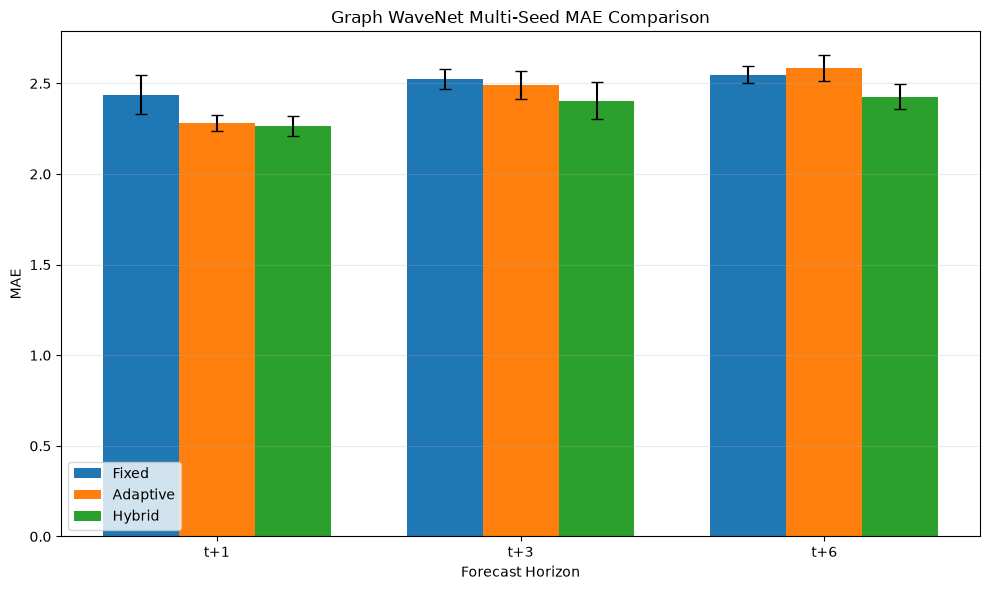

In [35]:
# ============================================================
# MAE COMPARISON
# ============================================================

mode_order = ["fixed", "adaptive", "hybrid"]

horizon_order = ["t+1", "t+3", "t+6"]

x = np.arange(len(horizon_order))

width = 0.25


plt.figure(figsize=(10, 6))


for i, mode in enumerate(mode_order):
    temp = summary[summary["mode"] == mode].set_index("horizon").loc[horizon_order]

    plt.bar(
        x + (i - 1) * width,
        temp["MAE_mean"],
        width=width,
        yerr=temp["MAE_std"],
        capsize=4,
        label=mode.title(),
    )


plt.xticks(x, horizon_order)

plt.xlabel("Forecast Horizon")

plt.ylabel("MAE")

plt.title("Graph WaveNet Multi-Seed MAE Comparison")

plt.legend()

plt.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.show()

### RMSE Comparison

RMSE memberikan penalti lebih besar terhadap error prediksi yang besar.

Grafik ini digunakan untuk melihat apakah pola performa ketiga strategi graph tetap konsisten ketika error besar diberi bobot yang lebih tinggi.

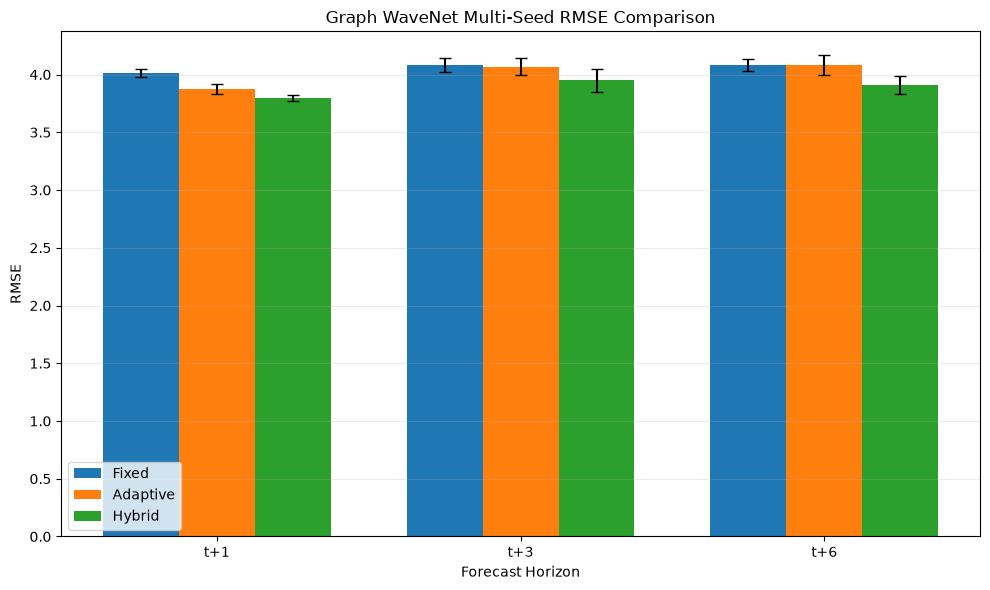

In [36]:
# ============================================================
# RMSE COMPARISON
# ============================================================

plt.figure(figsize=(10, 6))


for i, mode in enumerate(mode_order):
    temp = summary[summary["mode"] == mode].set_index("horizon").loc[horizon_order]

    plt.bar(
        x + (i - 1) * width,
        temp["RMSE_mean"],
        width=width,
        yerr=temp["RMSE_std"],
        capsize=4,
        label=mode.title(),
    )


plt.xticks(x, horizon_order)

plt.xlabel("Forecast Horizon")

plt.ylabel("RMSE")

plt.title("Graph WaveNet Multi-Seed RMSE Comparison")

plt.legend()

plt.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.show()

## 5. Improvement of Hybrid Model

Bagian ini menghitung persentase penurunan error pada model Hybrid dibandingkan:

- Fixed Graph
- Adaptive Graph

Rumus:

\[
\text{Improvement (\%)} =
\frac{\text{Error Baseline} - \text{Error Hybrid}}
{\text{Error Baseline}}
\times 100
\]

Semakin besar nilai improvement, semakin besar penurunan error yang diperoleh model Hybrid.

In [37]:
# ============================================================
# HYBRID IMPROVEMENT
# ============================================================

summary_idx = summary.set_index(["mode", "horizon"])


rows = []


for horizon in ["t+1", "t+3", "t+6"]:
    hybrid_mae = summary_idx.loc[("hybrid", horizon), "MAE_mean"]

    hybrid_rmse = summary_idx.loc[("hybrid", horizon), "RMSE_mean"]

    for baseline in ["fixed", "adaptive"]:
        baseline_mae = summary_idx.loc[(baseline, horizon), "MAE_mean"]

        baseline_rmse = summary_idx.loc[(baseline, horizon), "RMSE_mean"]

        mae_improvement = (baseline_mae - hybrid_mae) / baseline_mae * 100

        rmse_improvement = (baseline_rmse - hybrid_rmse) / baseline_rmse * 100

        rows.append(
            {
                "baseline": baseline,
                "horizon": horizon,
                "MAE improvement (%)": mae_improvement,
                "RMSE improvement (%)": rmse_improvement,
            }
        )


improvement_df = pd.DataFrame(rows)


display(improvement_df.round(2))

,baseline,horizon,MAE improvement (%),RMSE improvement (%)
0,fixed,t+1,7.13,5.34
1,adaptive,t+1,0.76,1.94
2,fixed,t+3,4.79,3.19
3,adaptive,t+3,3.49,2.92
4,fixed,t+6,4.79,4.21
5,adaptive,t+6,6.10,4.24


## 6. Learned Graph Analysis

Bagian ini menganalisis struktur graph yang digunakan oleh Graph WaveNet.

Tujuannya adalah membandingkan:

- Fixed geographic graph
- Adaptive learned graph
- Adaptive component pada Hybrid model

Analisis dilakukan untuk melihat apakah learned graph membentuk pola hubungan yang berbeda dari graph geografis.

In [38]:
# ============================================================
# LOAD GRAPH FILES
# ============================================================

FIXED_GRAPH_FILE = ROOT / "outputs" / "final_64" / "fixed_graph" / "fixed_graph_64.npz"

ADAPTIVE_GRAPH_FILE = RESULT_DIR / "graphwavenet_adaptive_seed42_adjacency.npy"

HYBRID_GRAPH_FILE = RESULT_DIR / "graphwavenet_hybrid_seed42_adjacency.npy"


# ============================================================
# CHECK FILES FIRST
# ============================================================

print("Fixed graph exists:", FIXED_GRAPH_FILE.exists())

print("Adaptive graph exists:", ADAPTIVE_GRAPH_FILE.exists())

print("Hybrid graph exists:", HYBRID_GRAPH_FILE.exists())


# ============================================================
# LOAD
# ============================================================

fixed_graph_npz = np.load(FIXED_GRAPH_FILE)

fixed_adj = fixed_graph_npz["directed_knn_adjacency"]

adaptive_adj = np.load(ADAPTIVE_GRAPH_FILE)

hybrid_adj = np.load(HYBRID_GRAPH_FILE)


# ============================================================
# VERIFY
# ============================================================

print("\nFixed graph keys:", fixed_graph_npz.files)

print("\nFixed adjacency:", fixed_adj.shape)

print("Adaptive adjacency:", adaptive_adj.shape)

print("Hybrid adaptive adjacency:", hybrid_adj.shape)

Fixed graph exists: True
Adaptive graph exists: True
Hybrid graph exists: True

Fixed graph keys: ['adjacency', 'adjacency_with_self', 'normalized_adjacency', 'distance_matrix', 'directed_knn_adjacency']

Fixed adjacency: (64, 64)
Adaptive adjacency: (64, 64)
Hybrid adaptive adjacency: (64, 64)


## 7. Struktur Fixed, Adaptive, dan Hybrid Graph

Fixed graph dibentuk dari hubungan geografis antarkoridor menggunakan directed K-nearest neighbors.

Adaptive graph dipelajari langsung oleh model selama training.

Pada Hybrid Graph WaveNet, model menggunakan keduanya secara bersamaan:

- forward fixed geographic graph
- reverse fixed geographic graph
- adaptive learned graph

Analisis berikut melihat seberapa terkonsentrasi hubungan yang dipelajari oleh Adaptive dan Hybrid.

In [39]:
# ============================================================
# LEARNED GRAPH STATISTICS
# ============================================================


def learned_graph_stats(adj, name):

    uniform_value = 1.0 / adj.shape[1]

    sorted_weights = np.sort(adj, axis=1)[:, ::-1]

    entropy = -np.sum(adj * np.log(adj + 1e-12), axis=1)

    normalized_entropy = entropy / np.log(adj.shape[1])

    return {
        "Graph": name,
        "Minimum Weight": adj.min(),
        "Maximum Weight": adj.max(),
        "Mean Top-1 Weight": sorted_weights[:, 0].mean(),
        "Mean Top-5 Weight Mass": sorted_weights[:, :5].sum(axis=1).mean(),
        "Normalized Entropy": normalized_entropy.mean(),
        "Deviation from Uniform": np.abs(adj - uniform_value).mean(),
    }


graph_stats_df = pd.DataFrame(
    [
        learned_graph_stats(adaptive_adj, "Adaptive"),
        learned_graph_stats(hybrid_adj, "Hybrid Adaptive Component"),
    ]
)


display(graph_stats_df.round(4))

,Graph,Minimum Weight,Maximum Weight,Mean Top-1 Weight,Mean Top-5 Weight Mass,Normalized Entropy,Deviation from Uniform
0,Adaptive,0.0092,0.1332,0.0573,0.1918,0.9720,0.0058
1,Hybrid Adaptive Component,0.0092,0.0548,0.0390,0.1525,0.9821,0.0051


### Konsentrasi Learned Graph

Nilai Top-1 menunjukkan rata-rata bobot hubungan terkuat untuk setiap node.

Nilai Top-5 menunjukkan total bobot rata-rata dari lima hubungan terkuat.

Nilai yang lebih besar menunjukkan learned graph yang lebih terkonsentrasi pada sejumlah kecil node.

,Graph,Top-1,Top-5,Top-10,Top-20
0,Adaptive,0.0573,0.1918,0.3114,0.4833
1,Hybrid,0.0390,0.1525,0.2739,0.4677


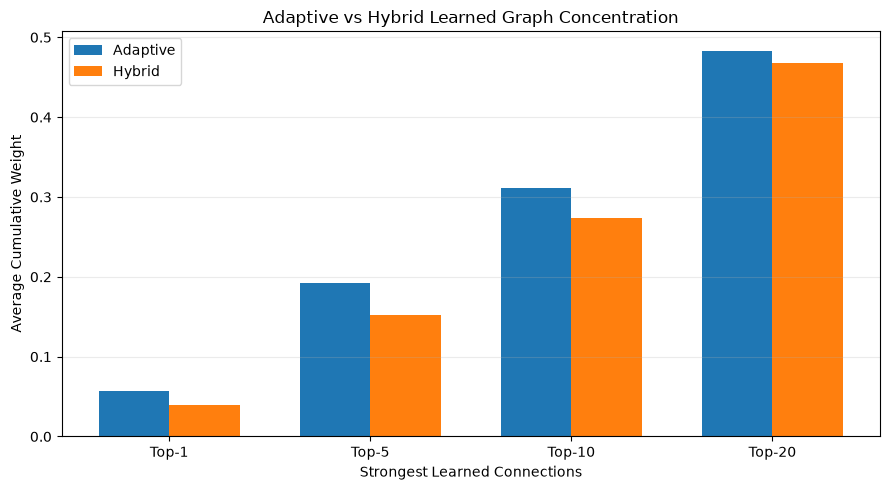

In [40]:
# ============================================================
# TOP-K MASS COMPARISON
# ============================================================

top_k_values = [1, 5, 10, 20]


def mean_topk_mass(adj, k):

    sorted_weights = np.sort(adj, axis=1)[:, ::-1]

    return sorted_weights[:, :k].sum(axis=1).mean()


topk_rows = []


for graph_name, adj in [("Adaptive", adaptive_adj), ("Hybrid", hybrid_adj)]:
    row = {"Graph": graph_name}

    for k in top_k_values:
        row[f"Top-{k}"] = mean_topk_mass(adj, k)

    topk_rows.append(row)


topk_df = pd.DataFrame(topk_rows)


display(topk_df.round(4))


# ============================================================
# PLOT
# ============================================================

x = np.arange(len(top_k_values))

width = 0.35


plt.figure(figsize=(9, 5))


for i, graph_name in enumerate(["Adaptive", "Hybrid"]):
    values = (
        topk_df[topk_df["Graph"] == graph_name][["Top-1", "Top-5", "Top-10", "Top-20"]]
        .iloc[0]
        .values
    )

    plt.bar(x + (i - 0.5) * width, values, width=width, label=graph_name)


plt.xticks(x, ["Top-1", "Top-5", "Top-10", "Top-20"])

plt.ylabel("Average Cumulative Weight")

plt.xlabel("Strongest Learned Connections")

plt.title("Adaptive vs Hybrid Learned Graph Concentration")

plt.legend()

plt.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.show()

## 8. Overlap with Fixed Geographic Graph

Fixed graph menggunakan 4 tetangga geografis terdekat untuk setiap node.

Pada bagian ini, empat koneksi terkuat dari learned graph dibandingkan dengan empat koneksi fixed geographic graph.

Overlap yang lebih tinggi berarti learned graph lebih banyak memilih hubungan yang sama dengan graph geografis.

Overlap yang lebih rendah menunjukkan bahwa model juga mempelajari dependency lain di luar hubungan geografis terdekat.

In [41]:
# ============================================================
# TOP-4 OVERLAP WITH FIXED GRAPH
# ============================================================

K = 4


def fixed_neighbors(adj, node, k=4):

    indices = np.where(adj[node] > 0)[0]

    return set(indices[:k])


def learned_topk_neighbors(adj, node, k=4):

    indices = np.argsort(adj[node])[::-1][:k]

    return set(indices)


def compute_overlap(fixed_adj, learned_adj, k=4):

    overlap_counts = []

    overlap_ratios = []

    for node in range(fixed_adj.shape[0]):
        fixed_set = fixed_neighbors(fixed_adj, node, k)

        learned_set = learned_topk_neighbors(learned_adj, node, k)

        overlap = len(fixed_set & learned_set)

        overlap_counts.append(overlap)

        overlap_ratios.append(overlap / k)

    return (np.array(overlap_counts), np.array(overlap_ratios))


adaptive_overlap_count, adaptive_overlap_ratio = compute_overlap(fixed_adj, adaptive_adj, K)


hybrid_overlap_count, hybrid_overlap_ratio = compute_overlap(fixed_adj, hybrid_adj, K)


overlap_summary = pd.DataFrame(
    {
        "Graph": ["Adaptive", "Hybrid"],
        "Mean Top-4 Overlap": [adaptive_overlap_count.mean(), hybrid_overlap_count.mean()],
        "Mean Overlap Ratio": [adaptive_overlap_ratio.mean(), hybrid_overlap_ratio.mean()],
    }
)


display(overlap_summary.round(4))

,Graph,Mean Top-4 Overlap,Mean Overlap Ratio
0,Adaptive,0.2500,0.0625
1,Hybrid,0.1562,0.0391


In [42]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 9. Demo Forecast Preparation

Demo akan menggunakan beberapa contoh dari test set, bukan hanya satu sample.

Contoh yang dipilih akan mewakili beberapa kondisi:

- Good case: prediksi Hybrid memiliki error kecil
- Typical case: error mendekati kondisi umum
- Difficult case: prediksi memiliki error relatif besar
- Comparison case: kondisi ketika Fixed atau Adaptive dapat mengungguli Hybrid

Tujuannya agar demo tidak hanya menampilkan contoh terbaik, tetapi menunjukkan karakter performa model pada beberapa kondisi.

In [43]:
# ============================================================
# INSPECT AVAILABLE FILES FOR DEMO
# ============================================================

print("=== RESULT FILES ===")

for path in sorted(RESULT_DIR.glob("*")):
    print(path.name)


print("\n=== MULTI-SEED FILES ===")

MULTISEED_DIR = RESULT_DIR / "multiseed"

if MULTISEED_DIR.exists():
    for path in sorted(MULTISEED_DIR.glob("*")):
        print(path.name)


# ============================================================
# LOAD TEST DATA
# ============================================================

TEST_FILE = DATA_DIR / "stgnn_test.npz"

# allow_pickle=True karena target_times dapat berupa object array
test_npz = np.load(TEST_FILE, allow_pickle=True)


print("\n=== TEST NPZ KEYS ===")

print(test_npz.files)


# ============================================================
# SHOW ARRAY INFORMATION
# ============================================================

for key in test_npz.files:
    arr = test_npz[key]

    print(key, "->", arr.shape, arr.dtype)


# ============================================================
# REQUIRED DATA FOR DEMO
# ============================================================

X_test = test_npz["X"]
y_test = test_npz["y"]
mask_test = test_npz["mask"]
target_times_test = test_npz["target_times"]


print("\n=== REQUIRED DEMO DATA ===")

print("X_test:", X_test.shape)

print("y_test:", y_test.shape)

print("mask_test:", mask_test.shape)

print("target_times_test:", target_times_test.shape)

=== RESULT FILES ===
graphwavenet_adaptive_seed42.weights.h5
graphwavenet_adaptive_seed42_adjacency.npy
graphwavenet_adaptive_seed42_history.csv
graphwavenet_adaptive_seed42_results.csv
graphwavenet_audited_seed42_comparison.csv
graphwavenet_fixed_seed42.weights.h5
graphwavenet_fixed_seed42_history.csv
graphwavenet_fixed_seed42_results.csv
graphwavenet_fixed_vs_adaptive_seed42.csv
graphwavenet_hybrid_seed42.weights.h5
graphwavenet_hybrid_seed42_adjacency.npy
graphwavenet_hybrid_seed42_history.csv
graphwavenet_hybrid_seed42_results.csv
graphwavenet_multiseed_all_results.csv
graphwavenet_multiseed_summary.csv
multiseed

=== MULTI-SEED FILES ===
graphwavenet_adaptive_seed123.weights.h5
graphwavenet_adaptive_seed123_adjacency.npy
graphwavenet_adaptive_seed123_history.csv
graphwavenet_adaptive_seed123_results.csv
graphwavenet_adaptive_seed2026.weights.h5
graphwavenet_adaptive_seed2026_adjacency.npy
graphwavenet_adaptive_seed2026_history.csv
graphwavenet_adaptive_seed2026_results.csv
graphwa

## Graph WaveNet Model Definition

Notebook analisis ini menggunakan arsitektur Graph WaveNet yang sama dengan notebook training.

Definisi model diperlukan untuk membangun kembali struktur jaringan sebelum memuat weight hasil training.

Arsitektur mencakup:

- gated dilated temporal convolution
- diffusion graph convolution
- fixed graph support
- adaptive learned graph
- hybrid fixed + adaptive graph
- skip connection
- residual connection
- output head untuk t+1, t+3, dan t+6

In [44]:
# ============================================================
# GRAPH WAVENET CONFIG
# ============================================================

GW_BLOCKS = 4
GW_LAYERS = 2
GW_KERNEL_SIZE = 2

GW_RESIDUAL_CHANNELS = 32
GW_DILATION_CHANNELS = 32
GW_SKIP_CHANNELS = 256
GW_END_CHANNELS = 512

GW_DIFFUSION_ORDER = 2
GW_ADAPTIVE_EMBED_DIM = 10
GW_DROPOUT = 0.3

GW_RECEPTIVE_FIELD = 13


# ============================================================
# GRAPH PROPAGATION
# ============================================================


def graph_propagate(x, support):
    """
    x:
        (batch, time, node, channel)

    support:
        (node, node)
    """

    return tf.einsum("btnc,nm->btmc", x, support)


# ============================================================
# DIFFUSION GRAPH CONVOLUTION
# ============================================================


class DiffusionGraphConv(tf.keras.layers.Layer):
    def __init__(self, output_channels, order=2, dropout=0.0, **kwargs):

        super().__init__(**kwargs)

        self.output_channels = output_channels

        self.order = order

        self.projection = tf.keras.layers.Dense(output_channels)

        self.dropout = tf.keras.layers.Dropout(dropout)

    def call(self, x, supports, training=False):

        outputs = [x]

        for support in supports:
            x1 = graph_propagate(x, support)

            outputs.append(x1)

            xk = x1

            for _ in range(2, self.order + 1):
                xk = graph_propagate(xk, support)

                outputs.append(xk)

        h = tf.concat(outputs, axis=-1)

        h = self.projection(h)

        h = self.dropout(h, training=training)

        return h


# ============================================================
# ADAPTIVE ADJACENCY
# ============================================================


class AdaptiveAdjacency(tf.keras.layers.Layer):
    def __init__(self, num_nodes, embed_dim=10, **kwargs):

        super().__init__(**kwargs)

        self.num_nodes = num_nodes

        self.embed_dim = embed_dim

    def build(self, input_shape):

        self.nodevec1 = self.add_weight(
            name="nodevec1",
            shape=(self.num_nodes, self.embed_dim),
            initializer=tf.keras.initializers.RandomNormal(stddev=0.1),
            trainable=True,
        )

        self.nodevec2 = self.add_weight(
            name="nodevec2",
            shape=(self.embed_dim, self.num_nodes),
            initializer=tf.keras.initializers.RandomNormal(stddev=0.1),
            trainable=True,
        )

        super().build(input_shape)

    def call(self, inputs=None):

        logits = tf.matmul(self.nodevec1, self.nodevec2)

        logits = tf.nn.relu(logits)

        adjacency = tf.nn.softmax(logits, axis=1)

        return adjacency


# ============================================================
# GATED TEMPORAL CONVOLUTION
# ============================================================


class GatedTemporalConv(tf.keras.layers.Layer):
    def __init__(self, channels, kernel_size, dilation, **kwargs):

        super().__init__(**kwargs)

        self.filter_conv = tf.keras.layers.Conv2D(
            filters=channels,
            kernel_size=(kernel_size, 1),
            dilation_rate=(dilation, 1),
            padding="valid",
        )

        self.gate_conv = tf.keras.layers.Conv2D(
            filters=channels,
            kernel_size=(kernel_size, 1),
            dilation_rate=(dilation, 1),
            padding="valid",
        )

    def call(self, x):

        filter_out = tf.math.tanh(self.filter_conv(x))

        gate_out = tf.math.sigmoid(self.gate_conv(x))

        return filter_out * gate_out


# ============================================================
# ONE GRAPH WAVENET LAYER
# ============================================================


class GraphWaveNetLayer(tf.keras.layers.Layer):
    def __init__(
        self,
        residual_channels,
        dilation_channels,
        skip_channels,
        kernel_size,
        dilation,
        diffusion_order,
        dropout,
        **kwargs,
    ):

        super().__init__(**kwargs)

        self.temporal = GatedTemporalConv(
            channels=dilation_channels, kernel_size=kernel_size, dilation=dilation
        )

        self.skip_conv = tf.keras.layers.Conv2D(filters=skip_channels, kernel_size=(1, 1))

        self.graph_conv = DiffusionGraphConv(
            output_channels=residual_channels, order=diffusion_order, dropout=dropout
        )

        self.batch_norm = tf.keras.layers.BatchNormalization()

    def call(self, x, supports, training=False):

        residual = x

        # temporal convolution
        x = self.temporal(x)

        # skip connection
        skip = self.skip_conv(x)

        # graph convolution
        x = self.graph_conv(x, supports, training=training)

        # crop residual to same temporal length
        residual = residual[:, -tf.shape(x)[1] :, :, :]

        x = x + residual

        x = self.batch_norm(x, training=training)

        return (x, skip)


# ============================================================
# GRAPH WAVENET BACKBONE
# ============================================================


class GraphWaveNetBackbone(tf.keras.layers.Layer):
    def __init__(
        self,
        residual_channels=32,
        dilation_channels=32,
        skip_channels=256,
        kernel_size=2,
        blocks=4,
        layers=2,
        diffusion_order=2,
        dropout=0.3,
        receptive_field=13,
        **kwargs,
    ):

        super().__init__(**kwargs)

        self.receptive_field = receptive_field

        self.start_conv = tf.keras.layers.Conv2D(filters=residual_channels, kernel_size=(1, 1))

        self.gw_layers = []

        for block in range(blocks):
            dilation = 1

            for layer in range(layers):
                gw_layer = GraphWaveNetLayer(
                    residual_channels=residual_channels,
                    dilation_channels=dilation_channels,
                    skip_channels=skip_channels,
                    kernel_size=kernel_size,
                    dilation=dilation,
                    diffusion_order=diffusion_order,
                    dropout=dropout,
                    name=(f"gw_block_{block + 1}_layer_{layer + 1}"),
                )

                self.gw_layers.append(gw_layer)

                dilation *= 2

    def call(self, x, supports, training=False):

        # ====================================================
        # LEFT PADDING
        # ====================================================

        time_length = tf.shape(x)[1]

        pad_amount = tf.maximum(self.receptive_field - time_length, 0)

        x = tf.pad(x, [[0, 0], [pad_amount, 0], [0, 0], [0, 0]])

        # ====================================================
        # START CONV
        # ====================================================

        x = self.start_conv(x)

        skip_total = None

        # ====================================================
        # STACK GRAPH WAVENET LAYERS
        # ====================================================

        for layer in self.gw_layers:
            x, skip = layer(x, supports, training=training)

            if skip_total is None:
                skip_total = skip

            else:
                min_time = tf.minimum(tf.shape(skip_total)[1], tf.shape(skip)[1])

                skip_total = skip_total[:, -min_time:, :, :] + skip[:, -min_time:, :, :]

        return (x, skip_total)


# ============================================================
# OUTPUT HEAD
# ============================================================


class GraphWaveNetHead(tf.keras.layers.Layer):
    def __init__(self, end_channels, num_horizons, **kwargs):

        super().__init__(**kwargs)

        self.end_conv_1 = tf.keras.layers.Conv2D(filters=end_channels, kernel_size=(1, 1))

        self.end_conv_2 = tf.keras.layers.Conv2D(filters=num_horizons, kernel_size=(1, 1))

    def call(self, skip):

        x = tf.nn.relu(skip)

        x = self.end_conv_1(x)

        x = tf.nn.relu(x)

        x = self.end_conv_2(x)

        # expected:
        # (B, 1, N, H)

        x = tf.squeeze(x, axis=1)

        # (B, N, H)
        # ->
        # (B, H, N)

        x = tf.transpose(x, perm=[0, 2, 1])

        return x


# ============================================================
# COMPLETE GRAPH WAVENET
# ============================================================


class GraphWaveNetModel(tf.keras.Model):
    def __init__(self, mode, fixed_supports, num_nodes, num_horizons, **kwargs):

        super().__init__(**kwargs)

        mode = mode.lower()

        if mode not in ["fixed", "adaptive", "hybrid"]:
            raise ValueError("mode must be fixed, adaptive, or hybrid")

        self.mode = mode

        self.fixed_supports = fixed_supports

        # ====================================================
        # ADAPTIVE GRAPH
        # ====================================================

        if mode in ["adaptive", "hybrid"]:
            self.adaptive_graph = AdaptiveAdjacency(
                num_nodes=num_nodes, embed_dim=GW_ADAPTIVE_EMBED_DIM, name="adaptive_adjacency"
            )

        else:
            self.adaptive_graph = None

        # ====================================================
        # BACKBONE
        # ====================================================

        self.backbone = GraphWaveNetBackbone(
            residual_channels=GW_RESIDUAL_CHANNELS,
            dilation_channels=GW_DILATION_CHANNELS,
            skip_channels=GW_SKIP_CHANNELS,
            kernel_size=GW_KERNEL_SIZE,
            blocks=GW_BLOCKS,
            layers=GW_LAYERS,
            diffusion_order=GW_DIFFUSION_ORDER,
            dropout=GW_DROPOUT,
            receptive_field=GW_RECEPTIVE_FIELD,
            name="graph_wavenet_backbone",
        )

        # ====================================================
        # HEAD
        # ====================================================

        self.head = GraphWaveNetHead(
            end_channels=GW_END_CHANNELS, num_horizons=num_horizons, name="graph_wavenet_head"
        )

    def call(self, x, training=False):

        supports = []

        # ====================================================
        # FIXED SUPPORTS
        # ====================================================

        if self.mode in ["fixed", "hybrid"]:
            supports.extend(self.fixed_supports)

        # ====================================================
        # ADAPTIVE SUPPORT
        # ====================================================

        if self.mode in ["adaptive", "hybrid"]:
            adaptive_support = self.adaptive_graph(x)

            supports.append(adaptive_support)

        # ====================================================
        # BACKBONE
        # ====================================================

        _, skip = self.backbone(x, supports, training=training)

        # ====================================================
        # OUTPUT
        # ====================================================

        return self.head(skip)


print("GraphWaveNetModel definition ready.")

GraphWaveNetModel definition ready.


## 10. Generate Test Predictions

Bagian ini memuat kembali model Graph WaveNet seed 42 untuk:

- Fixed
- Adaptive
- Hybrid

Kemudian dilakukan inference pada seluruh test set.

Hasil prediksi akan digunakan untuk memilih beberapa contoh demo:

- good case
- typical case
- difficult case
- comparison case

Prediksi dikembalikan ke satuan kecepatan asli menggunakan scaler yang sama dengan proses training.

In [45]:
# ============================================================
# IMPORT
# ============================================================

import tensorflow as tf

print("TensorFlow version:", tf.__version__)


# ============================================================
# LOAD TEST DATA
# ============================================================

X_test = test_npz["X"]
y_test = test_npz["y"]
mask_test = test_npz["mask"]


print("\nTest X:", X_test.shape)

print("Test y:", y_test.shape)

print("Test mask:", mask_test.shape)


# ============================================================
# LOAD SCALER
# ============================================================

SCALER_FILE = DATA_DIR / "stgnn_scaler.npz"

scaler_npz = np.load(SCALER_FILE)

scaler_mean = float(np.asarray(scaler_npz["mean"]).reshape(-1)[0])

scaler_scale = float(np.asarray(scaler_npz["scale"]).reshape(-1)[0])


print("\nScaler mean:", scaler_mean)

print("Scaler scale:", scaler_scale)


# ============================================================
# PREPARE FIXED SUPPORTS
# ============================================================

A_directed = fixed_graph_npz["directed_knn_adjacency"].astype(np.float32)


def row_normalize(A):

    row_sum = A.sum(axis=1, keepdims=True)

    return A / np.maximum(row_sum, 1e-12)


A_forward = row_normalize(A_directed)

A_reverse = row_normalize(A_directed.T)


FIXED_SUPPORTS = [
    tf.constant(A_forward, dtype=tf.float32),
    tf.constant(A_reverse, dtype=tf.float32),
]


print("\nFixed support 1:", FIXED_SUPPORTS[0].shape)

print("Fixed support 2:", FIXED_SUPPORTS[1].shape)


# ============================================================
# LOAD MODEL FUNCTION
# ============================================================


def load_seed42_model(mode):

    tf.keras.backend.clear_session()

    model = GraphWaveNetModel(
        mode=mode,
        fixed_supports=FIXED_SUPPORTS,
        num_nodes=64,
        num_horizons=3,
        name=f"graphwavenet_{mode}_seed42",
    )

    # Build model structure
    _ = model(tf.convert_to_tensor(X_test[:1], dtype=tf.float32), training=False)

    # Weight file
    weights_file = RESULT_DIR / f"graphwavenet_{mode}_seed42.weights.h5"

    if not weights_file.exists():
        raise FileNotFoundError(f"Weight file tidak ditemukan: {weights_file}")

    model.load_weights(weights_file)

    print(f"{mode.title()} loaded:", weights_file.name)

    return model


# ============================================================
# LOAD SEED 42 MODELS
# ============================================================

fixed_model = load_seed42_model("fixed")

adaptive_model = load_seed42_model("adaptive")

hybrid_model = load_seed42_model("hybrid")


# ============================================================
# TEST INFERENCE
# ============================================================

fixed_pred_std = fixed_model.predict(X_test, batch_size=32, verbose=0)

adaptive_pred_std = adaptive_model.predict(X_test, batch_size=32, verbose=0)

hybrid_pred_std = hybrid_model.predict(X_test, batch_size=32, verbose=0)


# ============================================================
# INVERSE SCALING
# ============================================================


def inverse_scale(arr):

    return arr * scaler_scale + scaler_mean


y_test_real = inverse_scale(y_test)

fixed_pred_real = inverse_scale(fixed_pred_std)

adaptive_pred_real = inverse_scale(adaptive_pred_std)

hybrid_pred_real = inverse_scale(hybrid_pred_std)


# ============================================================
# VERIFY OUTPUT
# ============================================================

print("\n=== PREDICTION SHAPES ===")

print("Actual:", y_test_real.shape)

print("Fixed:", fixed_pred_real.shape)

print("Adaptive:", adaptive_pred_real.shape)

print("Hybrid:", hybrid_pred_real.shape)


print("\nPrediction generation finished.")

TensorFlow version: 2.21.0

Test X: (93, 12, 64, 1)
Test y: (93, 3, 64)
Test mask: (93, 3, 64)

Scaler mean: 30.50661914460285
Scaler scale: 11.331123867533398

Fixed support 1: (64, 64)
Fixed support 2: (64, 64)
Fixed loaded: graphwavenet_fixed_seed42.weights.h5
Adaptive loaded: graphwavenet_adaptive_seed42.weights.h5
Hybrid loaded: graphwavenet_hybrid_seed42.weights.h5

=== PREDICTION SHAPES ===
Actual: (93, 3, 64)
Fixed: (93, 3, 64)
Adaptive: (93, 3, 64)
Hybrid: (93, 3, 64)

Prediction generation finished.


## 11. Select Representative Demo Cases

Demo tidak hanya menggunakan satu sample.

Beberapa contoh dipilih berdasarkan error prediksi Hybrid agar dapat menunjukkan berbagai kondisi performa model:

- Good case: Hybrid memiliki error rendah
- Typical case: error Hybrid mendekati median
- Difficult case: Hybrid memiliki error tinggi
- Comparison case: Fixed atau Adaptive mengungguli Hybrid

Pemilihan dilakukan dari seluruh pasangan sample dan corridor yang memiliki target valid.

In [46]:
# ============================================================
# BUILD SAMPLE-CORRIDOR ERROR TABLE
# ============================================================

rows = []

num_samples = y_test_real.shape[0]
num_nodes = y_test_real.shape[2]


for sample_idx in range(num_samples):
    for node_idx in range(num_nodes):
        valid_horizons = mask_test[sample_idx, :, node_idx]

        if not np.any(valid_horizons):
            continue

        actual = y_test_real[sample_idx, :, node_idx]

        fixed_pred = fixed_pred_real[sample_idx, :, node_idx]

        adaptive_pred = adaptive_pred_real[sample_idx, :, node_idx]

        hybrid_pred = hybrid_pred_real[sample_idx, :, node_idx]

        fixed_abs = np.abs(fixed_pred - actual)

        adaptive_abs = np.abs(adaptive_pred - actual)

        hybrid_abs = np.abs(hybrid_pred - actual)

        fixed_mae = float(fixed_abs[valid_horizons].mean())

        adaptive_mae = float(adaptive_abs[valid_horizons].mean())

        hybrid_mae = float(hybrid_abs[valid_horizons].mean())

        rows.append(
            {
                "sample_idx": sample_idx,
                "node_idx": node_idx,
                "valid_horizons": int(valid_horizons.sum()),
                "fixed_mae": fixed_mae,
                "adaptive_mae": adaptive_mae,
                "hybrid_mae": hybrid_mae,
                "best_model": min(
                    {"fixed": fixed_mae, "adaptive": adaptive_mae, "hybrid": hybrid_mae},
                    key={"fixed": fixed_mae, "adaptive": adaptive_mae, "hybrid": hybrid_mae}.get,
                ),
            }
        )


case_df = pd.DataFrame(rows)


print("Total valid sample-corridor cases:", len(case_df))

print("\nBest model counts:")

display(case_df["best_model"].value_counts().rename_axis("best_model").reset_index(name="count"))


print("\nHybrid MAE distribution:")

display(case_df["hybrid_mae"].describe())

Total valid sample-corridor cases: 5952

Best model counts:


,best_model,count
0,hybrid,2122
1,adaptive,2066
2,fixed,1764



Hybrid MAE distribution:


count    5952.000000
mean        2.318889
std         2.774098
min         0.001629
25%         0.648138
50%         1.541949
75%         2.978320
max        37.750835
Name: hybrid_mae, dtype: float64

## 12. Representative Demo Case Selection

Beberapa contoh demo dipilih secara objektif berdasarkan distribusi error Hybrid.

Case yang dipilih:

- Good 1: error Hybrid mendekati percentile 10%
- Good 2: error Hybrid mendekati percentile 25%
- Typical 1: error Hybrid mendekati median
- Typical 2: error Hybrid mendekati percentile 60%
- Difficult 1: error Hybrid mendekati percentile 85%
- Difficult 2: error Hybrid mendekati percentile 95%
- Fixed Wins: contoh ketika Fixed mengungguli Hybrid dengan margin besar
- Adaptive Wins: contoh ketika Adaptive mengungguli Hybrid dengan margin besar

Pendekatan ini digunakan agar demo tidak hanya menampilkan contoh terbaik.

In [47]:
# ============================================================
# SELECT REPRESENTATIVE CASES
# ============================================================


def closest_to_quantile(df, column, quantile):
    target = df[column].quantile(quantile)

    idx = df[column].sub(target).abs().idxmin()

    return df.loc[idx].copy()


selected_cases = []


# ============================================================
# GOOD CASES
# ============================================================

case = closest_to_quantile(case_df, "hybrid_mae", 0.10)

case["case_type"] = "Good 1 (P10)"
selected_cases.append(case)


case = closest_to_quantile(case_df, "hybrid_mae", 0.25)

case["case_type"] = "Good 2 (P25)"
selected_cases.append(case)


# ============================================================
# TYPICAL CASES
# ============================================================

case = closest_to_quantile(case_df, "hybrid_mae", 0.50)

case["case_type"] = "Typical 1 (Median)"
selected_cases.append(case)


case = closest_to_quantile(case_df, "hybrid_mae", 0.60)

case["case_type"] = "Typical 2 (P60)"
selected_cases.append(case)


# ============================================================
# DIFFICULT CASES
# ============================================================

case = closest_to_quantile(case_df, "hybrid_mae", 0.85)

case["case_type"] = "Difficult 1 (P85)"
selected_cases.append(case)


case = closest_to_quantile(case_df, "hybrid_mae", 0.95)

case["case_type"] = "Difficult 2 (P95)"
selected_cases.append(case)


# ============================================================
# FIXED BEATS HYBRID
# ============================================================

fixed_win_df = case_df[case_df["best_model"] == "fixed"].copy()

fixed_win_df["hybrid_gap"] = fixed_win_df["hybrid_mae"] - fixed_win_df["fixed_mae"]

fixed_case = fixed_win_df.sort_values("hybrid_gap", ascending=False).iloc[0].copy()

fixed_case["case_type"] = "Comparison - Fixed Wins"

selected_cases.append(fixed_case)


# ============================================================
# ADAPTIVE BEATS HYBRID
# ============================================================

adaptive_win_df = case_df[case_df["best_model"] == "adaptive"].copy()

adaptive_win_df["hybrid_gap"] = adaptive_win_df["hybrid_mae"] - adaptive_win_df["adaptive_mae"]

adaptive_case = adaptive_win_df.sort_values("hybrid_gap", ascending=False).iloc[0].copy()

adaptive_case["case_type"] = "Comparison - Adaptive Wins"

selected_cases.append(adaptive_case)


# ============================================================
# FINAL TABLE
# ============================================================

selected_cases_df = pd.DataFrame(selected_cases)


selected_cases_df = selected_cases_df[
    [
        "case_type",
        "sample_idx",
        "node_idx",
        "valid_horizons",
        "fixed_mae",
        "adaptive_mae",
        "hybrid_mae",
        "best_model",
    ]
].reset_index(drop=True)


display(selected_cases_df.round(4))

,case_type,sample_idx,node_idx,valid_horizons,fixed_mae,adaptive_mae,hybrid_mae,best_model
0,Good 1 (P10),75,57,2,5.9065,0.8512,0.2667,hybrid
1,Good 2 (P25),84,39,1,0.9758,0.8146,0.6481,hybrid
2,Typical 1 (Median),35,43,2,2.7006,2.3699,1.5417,hybrid
3,Typical 2 (P60),20,15,1,1.6535,4.1333,2.0153,fixed
4,Difficult 1 (P85),56,51,1,1.9115,1.0356,4.0544,adaptive
5,Difficult 2 (P95),65,39,2,5.5120,5.6779,7.0933,fixed
6,Comparison - Fixed Wins,10,13,1,2.6166,11.7443,16.4641,fixed
7,Comparison - Adaptive Wins,85,13,2,12.6610,6.4882,25.4104,adaptive


## 13. Refined Representative Cases

Untuk demo utama, dipilih case yang memiliki minimal dua target horizon valid.

Hal ini dilakukan agar setiap contoh dapat menunjukkan perilaku model pada lebih dari satu horizon prediksi.

Case yang dipilih tetap mencakup:

- good case
- typical case
- difficult case
- Fixed outperforming Hybrid
- Adaptive outperforming Hybrid

In [48]:
# ============================================================
# FILTER CASES WITH AT LEAST 2 VALID HORIZONS
# ============================================================

case_2h_df = case_df[case_df["valid_horizons"] >= 2].copy()

print("Cases with >= 2 valid horizons:", len(case_2h_df))


# ============================================================
# HELPER
# ============================================================


def closest_quantile_case(df, column, quantile):

    target = df[column].quantile(quantile)

    idx = df[column].sub(target).abs().idxmin()

    return df.loc[idx].copy()


refined_cases = []


# ============================================================
# GOOD
# ============================================================

for q, label in [(0.10, "Good 1"), (0.25, "Good 2")]:
    c = closest_quantile_case(case_2h_df, "hybrid_mae", q)

    c["case_type"] = label

    refined_cases.append(c)


# ============================================================
# TYPICAL
# ============================================================

for q, label in [(0.50, "Typical 1"), (0.60, "Typical 2")]:
    c = closest_quantile_case(case_2h_df, "hybrid_mae", q)

    c["case_type"] = label

    refined_cases.append(c)


# ============================================================
# DIFFICULT
# ============================================================

for q, label in [(0.85, "Difficult 1"), (0.95, "Difficult 2")]:
    c = closest_quantile_case(case_2h_df, "hybrid_mae", q)

    c["case_type"] = label

    refined_cases.append(c)


# ============================================================
# MODERATE FIXED-WINS CASE
# ============================================================

fixed_candidates = case_2h_df[case_2h_df["best_model"] == "fixed"].copy()

fixed_candidates["gap"] = fixed_candidates["hybrid_mae"] - fixed_candidates["fixed_mae"]

fixed_candidates = fixed_candidates[fixed_candidates["gap"] > 0]

fixed_case = closest_quantile_case(fixed_candidates, "gap", 0.75)

fixed_case["case_type"] = "Comparison - Fixed Wins"

refined_cases.append(fixed_case)


# ============================================================
# MODERATE ADAPTIVE-WINS CASE
# ============================================================

adaptive_candidates = case_2h_df[case_2h_df["best_model"] == "adaptive"].copy()

adaptive_candidates["gap"] = adaptive_candidates["hybrid_mae"] - adaptive_candidates["adaptive_mae"]

adaptive_candidates = adaptive_candidates[adaptive_candidates["gap"] > 0]

adaptive_case = closest_quantile_case(adaptive_candidates, "gap", 0.75)

adaptive_case["case_type"] = "Comparison - Adaptive Wins"

refined_cases.append(adaptive_case)


# ============================================================
# FINAL REFINED TABLE
# ============================================================

refined_cases_df = pd.DataFrame(refined_cases)


refined_cases_df = refined_cases_df[
    [
        "case_type",
        "sample_idx",
        "node_idx",
        "valid_horizons",
        "fixed_mae",
        "adaptive_mae",
        "hybrid_mae",
        "best_model",
    ]
].reset_index(drop=True)


display(refined_cases_df.round(4))

Cases with >= 2 valid horizons: 2944


,case_type,sample_idx,node_idx,valid_horizons,fixed_mae,adaptive_mae,hybrid_mae,best_model
0,Good 1,85,23,2,0.2860,0.7526,0.3147,fixed
1,Good 2,45,50,2,0.3790,1.0534,0.6703,fixed
2,Typical 1,19,6,2,1.3071,2.0756,1.5930,fixed
3,Typical 2,15,21,2,2.7485,1.9300,2.0806,adaptive
4,Difficult 1,1,47,2,4.2293,7.0265,3.9153,hybrid
5,Difficult 2,47,0,2,8.8070,9.5727,6.8046,hybrid
6,Comparison - Fixed Wins,73,60,2,2.8867,3.1473,3.8713,fixed
7,Comparison - Adaptive Wins,33,31,2,3.0425,0.6766,1.6438,adaptive


## 14. Actual vs Predicted Values for Representative Cases

Bagian ini menampilkan nilai aktual dan hasil prediksi untuk setiap representative case.

Untuk setiap case ditampilkan:

- sample index
- node index
- target time
- horizon
- actual speed
- Fixed prediction
- Adaptive prediction
- Hybrid prediction
- absolute error masing-masing model

Hanya horizon yang valid berdasarkan mask yang ditampilkan.

In [49]:
# ============================================================
# BUILD DETAILED DEMO TABLE
# ============================================================

HORIZON_NAMES = ["t+1", "t+3", "t+6"]

demo_rows = []


for _, case in refined_cases_df.iterrows():
    sample_idx = int(case["sample_idx"])

    node_idx = int(case["node_idx"])

    valid_mask = mask_test[sample_idx, :, node_idx]

    for h_idx, horizon in enumerate(HORIZON_NAMES):
        if not valid_mask[h_idx]:
            continue

        actual = float(y_test_real[sample_idx, h_idx, node_idx])

        fixed_pred = float(fixed_pred_real[sample_idx, h_idx, node_idx])

        adaptive_pred = float(adaptive_pred_real[sample_idx, h_idx, node_idx])

        hybrid_pred = float(hybrid_pred_real[sample_idx, h_idx, node_idx])

        demo_rows.append(
            {
                "case_type": case["case_type"],
                "sample_idx": sample_idx,
                "node_idx": node_idx,
                "horizon": horizon,
                "target_time": target_times_test[sample_idx, h_idx],
                "actual": actual,
                "fixed_pred": fixed_pred,
                "adaptive_pred": adaptive_pred,
                "hybrid_pred": hybrid_pred,
                "fixed_abs_error": abs(fixed_pred - actual),
                "adaptive_abs_error": abs(adaptive_pred - actual),
                "hybrid_abs_error": abs(hybrid_pred - actual),
            }
        )


demo_detail_df = pd.DataFrame(demo_rows)


display(demo_detail_df.round(3))

/var/folders/2x/yznypdvj28bc1rg2rmbjkpmc0000gn/T/ipykernel_75550/1219883130.py:133: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  demo_detail_df.round(3)


,case_type,sample_idx,node_idx,horizon,target_time,actual,fixed_pred,adaptive_pred,hybrid_pred,fixed_abs_error,adaptive_abs_error,hybrid_abs_error
0,Good 1,85,23,t+1,2026-09-11 00:00:00+00:00,25.0,24.786,24.002,24.387,0.214,0.998,0.613
1,Good 1,85,23,t+3,2026-09-11 02:00:00+00:00,25.0,24.642,24.493,25.017,0.358,0.507,0.017
2,Good 2,45,50,t+1,2026-09-09 08:00:00+00:00,17.0,17.069,18.259,17.786,0.069,1.259,0.786
3,Good 2,45,50,t+3,2026-09-09 10:00:00+00:00,18.0,18.689,17.153,18.555,0.689,0.847,0.555
4,Typical 1,19,6,t+1,2026-09-08 06:00:00+00:00,14.0,16.452,17.738,14.922,2.452,3.738,0.922
5,Typical 1,19,6,t+3,2026-09-08 08:00:00+00:00,17.0,17.163,16.587,14.736,0.163,0.413,2.264
6,Typical 2,15,21,t+1,2026-09-08 02:00:00+00:00,24.0,21.347,22.419,22.136,2.653,1.581,1.864
7,Typical 2,15,21,t+3,2026-09-08 04:00:00+00:00,24.0,21.156,21.721,21.702,2.844,2.279,2.298
8,Difficult 1,1,47,t+1,2026-09-07 12:00:00+00:00,26.0,31.204,32.074,31.007,5.204,6.074,5.007
9,Difficult 1,1,47,t+3,2026-09-07 14:00:00+00:00,28.0,31.254,35.979,30.824,3.254,7.979,2.824


## 15. Visual Comparison of Representative Cases

Grafik berikut membandingkan nilai aktual dengan prediksi:

- Fixed Graph WaveNet
- Adaptive Graph WaveNet
- Hybrid Graph WaveNet

untuk beberapa representative case.

Case dipilih untuk menunjukkan:

- kondisi error rendah
- kondisi tipikal
- kondisi sulit
- kondisi ketika Fixed mengungguli Hybrid
- kondisi ketika Adaptive mengungguli Hybrid

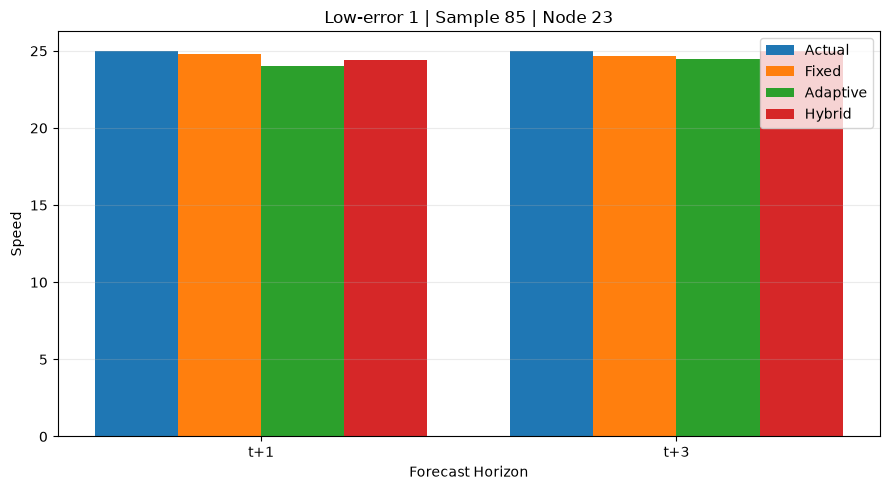

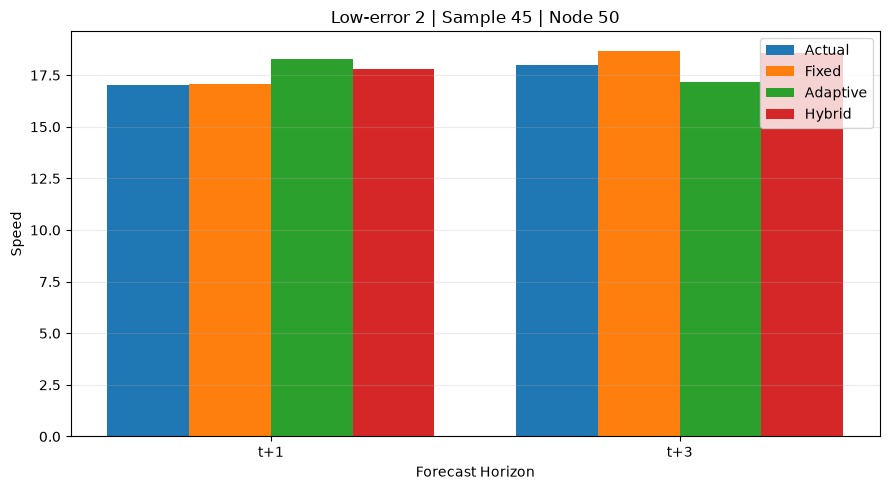

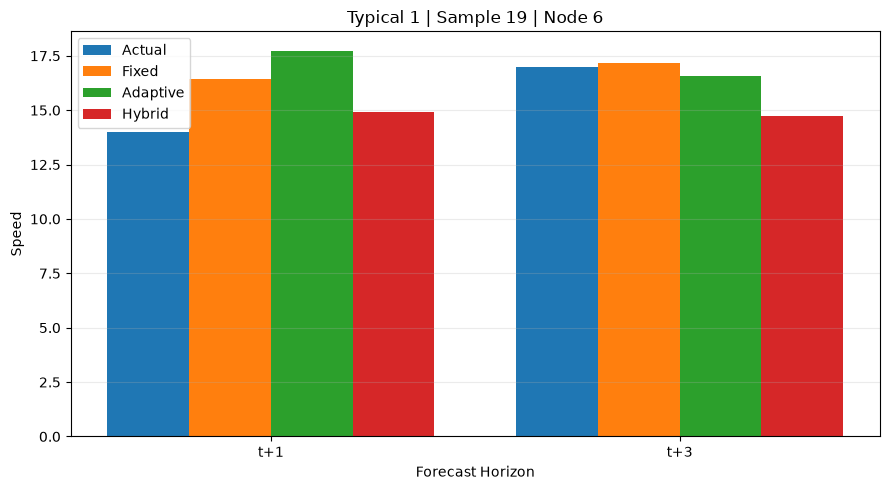

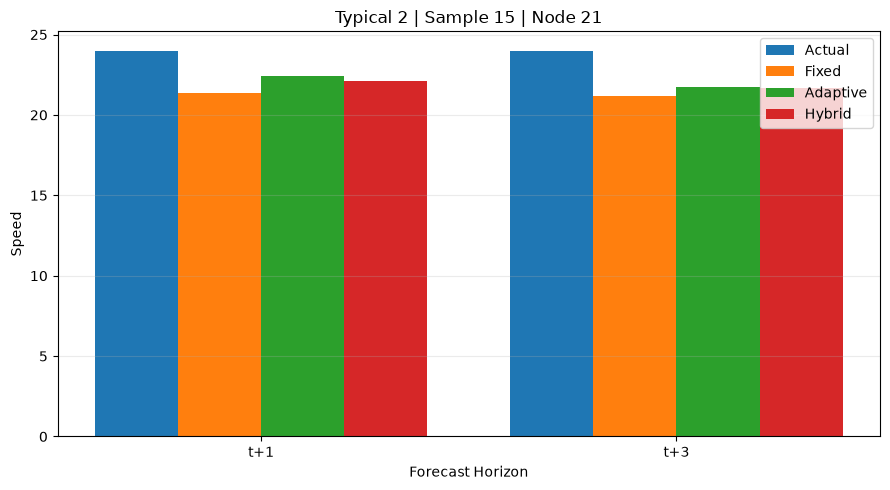

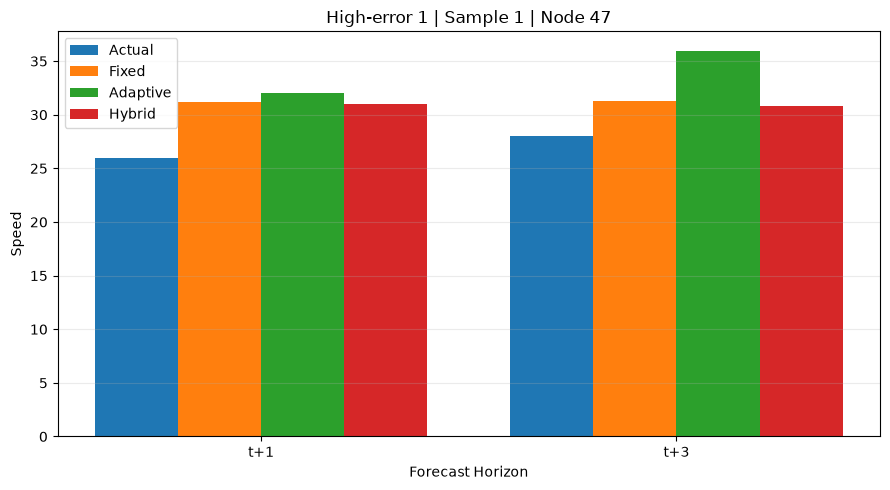

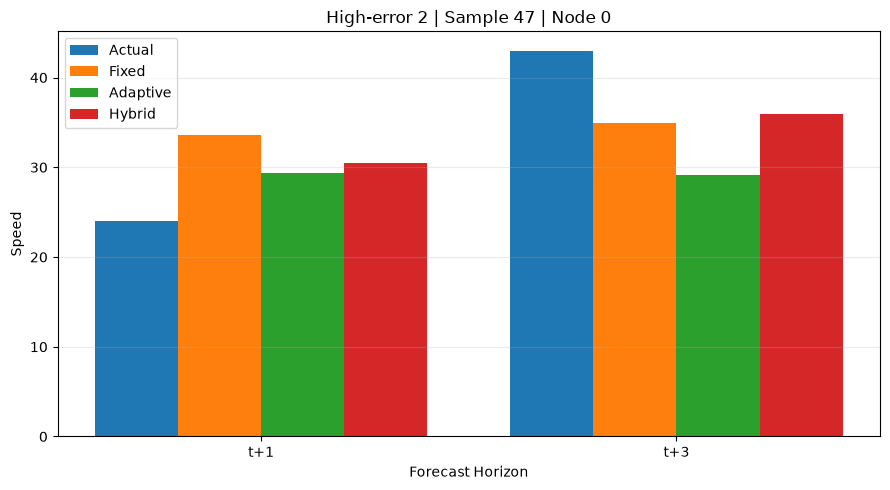

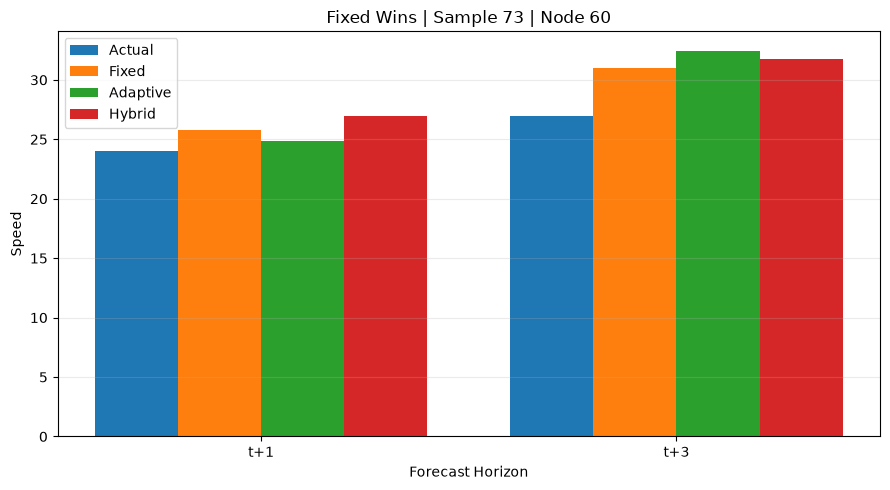

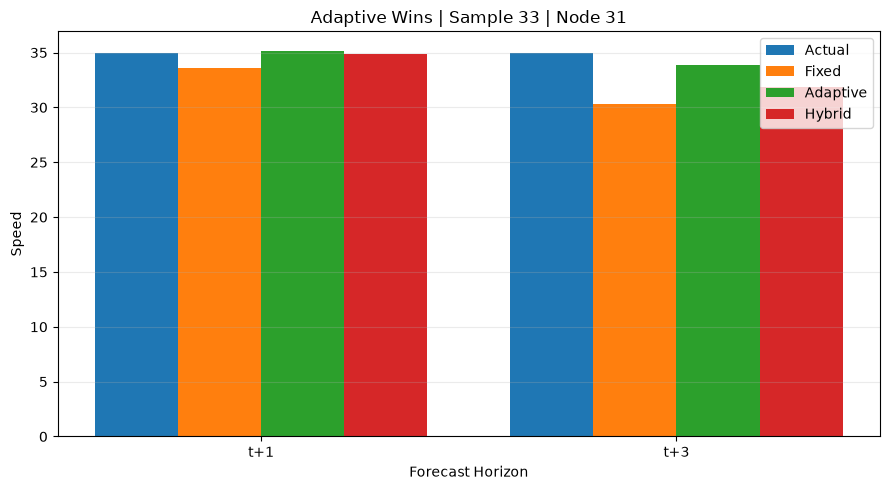

In [50]:
# ============================================================
# PLOT REPRESENTATIVE CASES
# ============================================================

case_label_map = {
    "Good 1": "Low-error 1",
    "Good 2": "Low-error 2",
    "Typical 1": "Typical 1",
    "Typical 2": "Typical 2",
    "Difficult 1": "High-error 1",
    "Difficult 2": "High-error 2",
    "Comparison - Fixed Wins": "Fixed Wins",
    "Comparison - Adaptive Wins": "Adaptive Wins",
}


for case_type in demo_detail_df["case_type"].unique():
    temp = demo_detail_df[demo_detail_df["case_type"] == case_type].copy()

    horizons = temp["horizon"].tolist()

    x = np.arange(len(horizons))

    width = 0.20

    plt.figure(figsize=(9, 5))

    plt.bar(x - 1.5 * width, temp["actual"], width, label="Actual")

    plt.bar(x - 0.5 * width, temp["fixed_pred"], width, label="Fixed")

    plt.bar(x + 0.5 * width, temp["adaptive_pred"], width, label="Adaptive")

    plt.bar(x + 1.5 * width, temp["hybrid_pred"], width, label="Hybrid")

    plt.xticks(x, horizons)

    plt.xlabel("Forecast Horizon")

    plt.ylabel("Speed")

    plt.title(
        f"{case_label_map.get(case_type, case_type)} "
        f"| Sample {int(temp['sample_idx'].iloc[0])} "
        f"| Node {int(temp['node_idx'].iloc[0])}"
    )

    plt.legend()

    plt.grid(axis="y", alpha=0.25)

    plt.tight_layout()

    plt.show()

## 16. Historical Input and Multi-Horizon Forecast Demo

Bagian ini memperlihatkan alur prediksi secara lebih intuitif.

Untuk setiap representative case ditampilkan:

- 12 timestep historical speed sebagai input model
- nilai aktual pada horizon yang valid
- prediksi Fixed Graph WaveNet
- prediksi Adaptive Graph WaveNet
- prediksi Hybrid Graph WaveNet

Sumbu waktu historis ditulis relatif terhadap waktu terakhir input:

- H-11 sampai H0 = historical input
- t+1, t+3, t+6 = forecast horizon

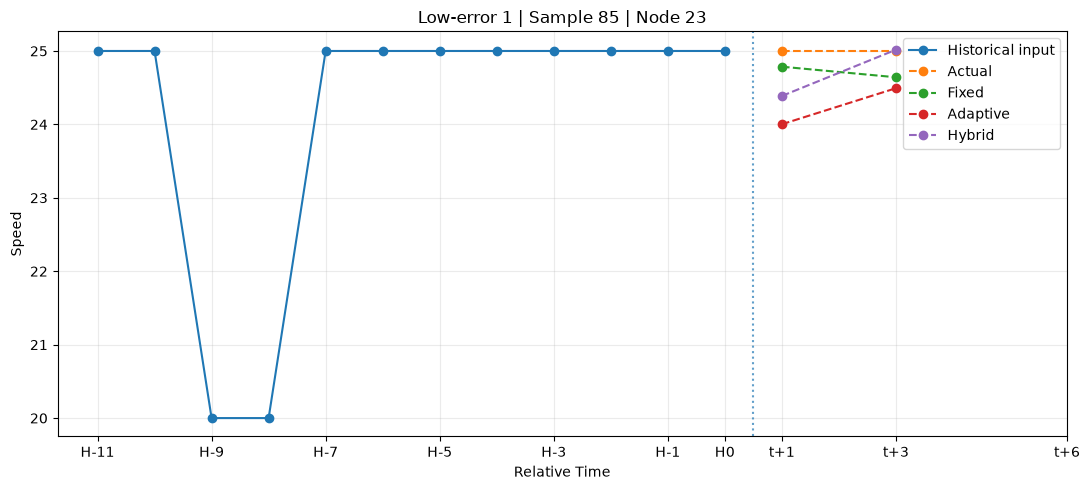

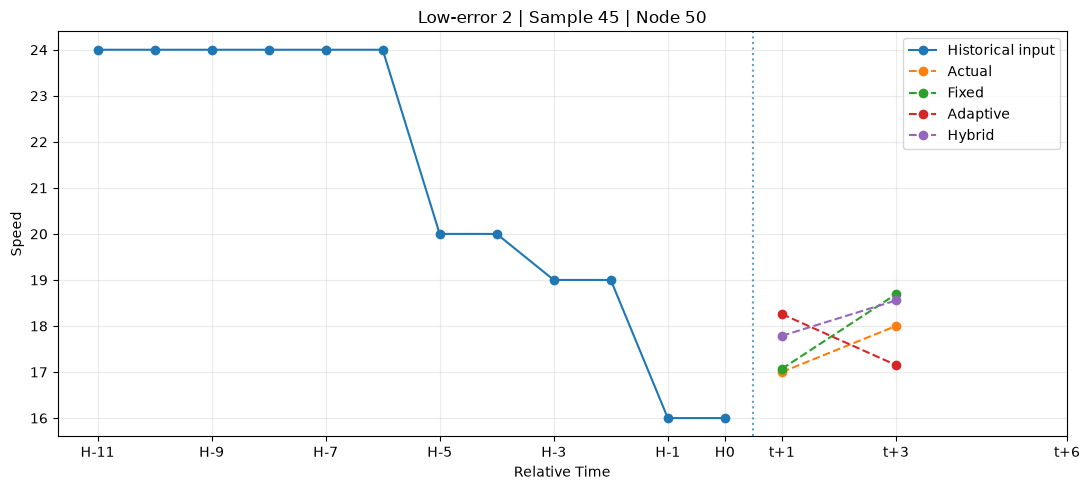

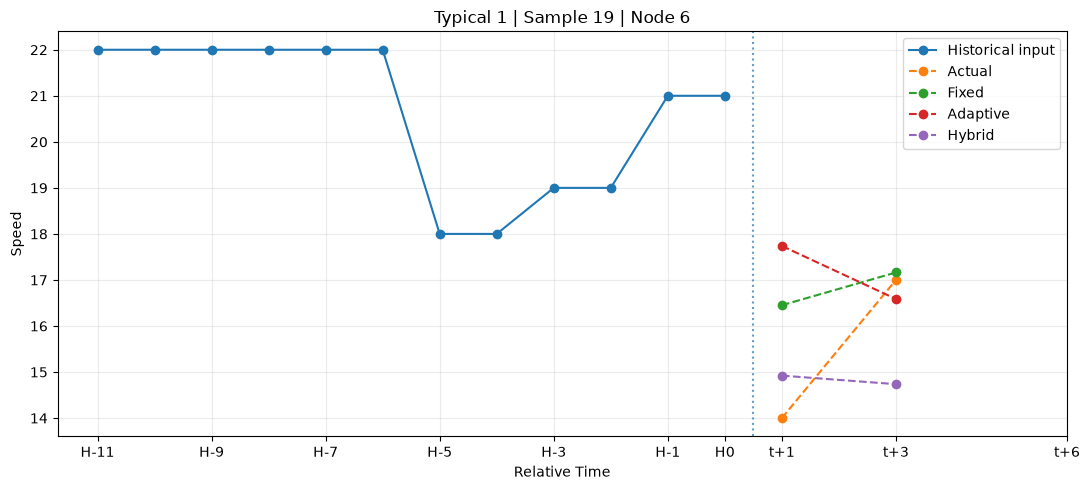

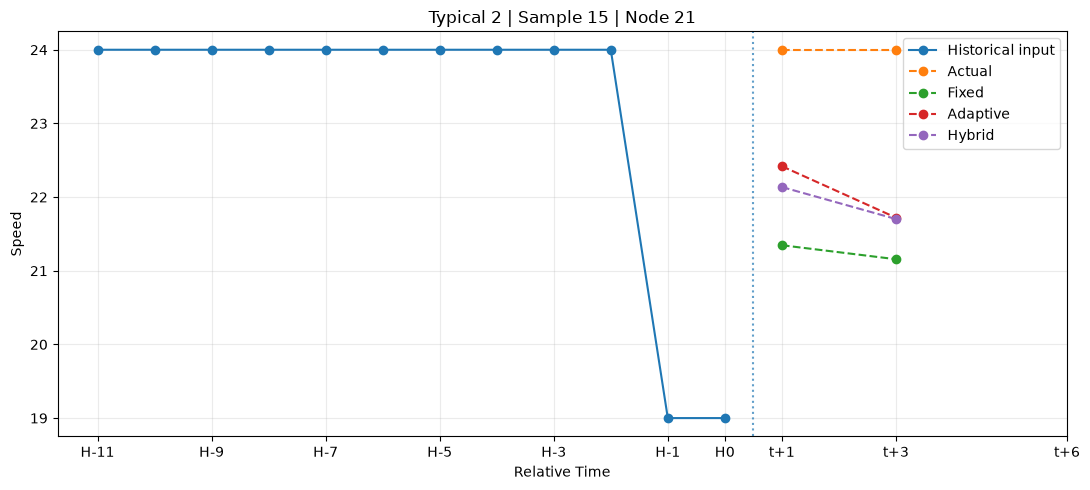

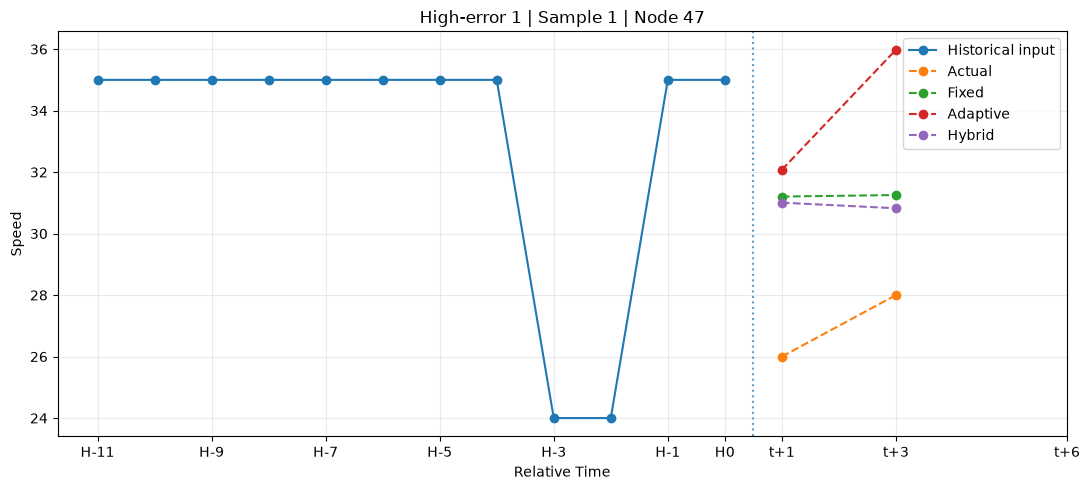

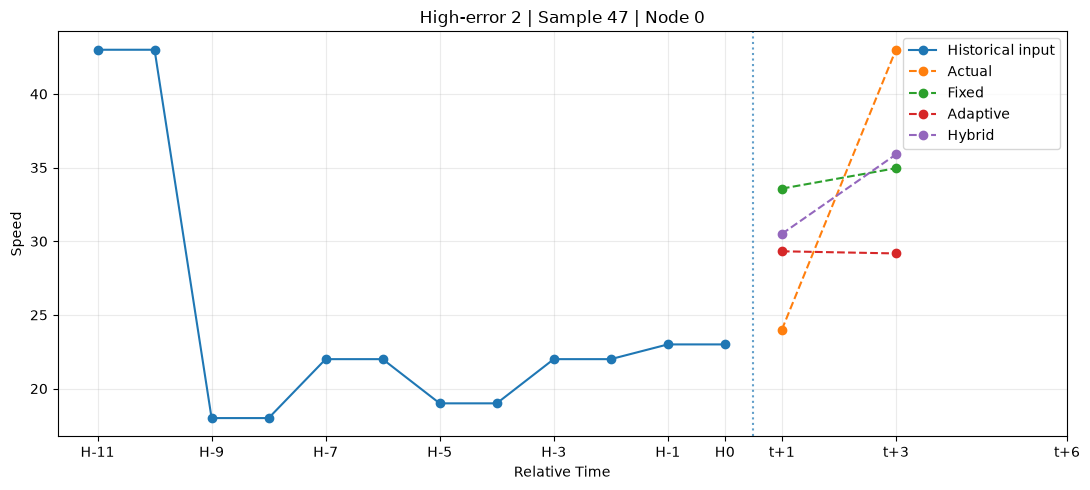

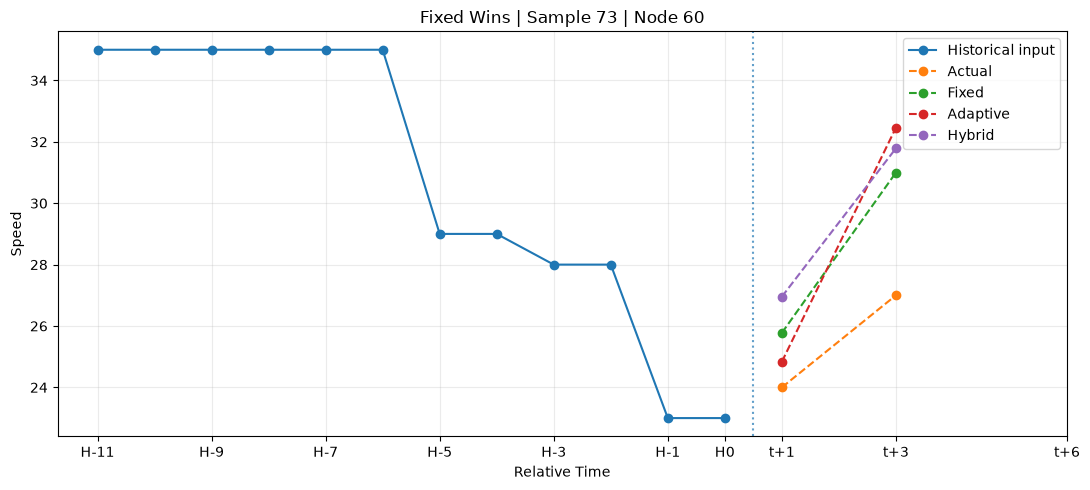

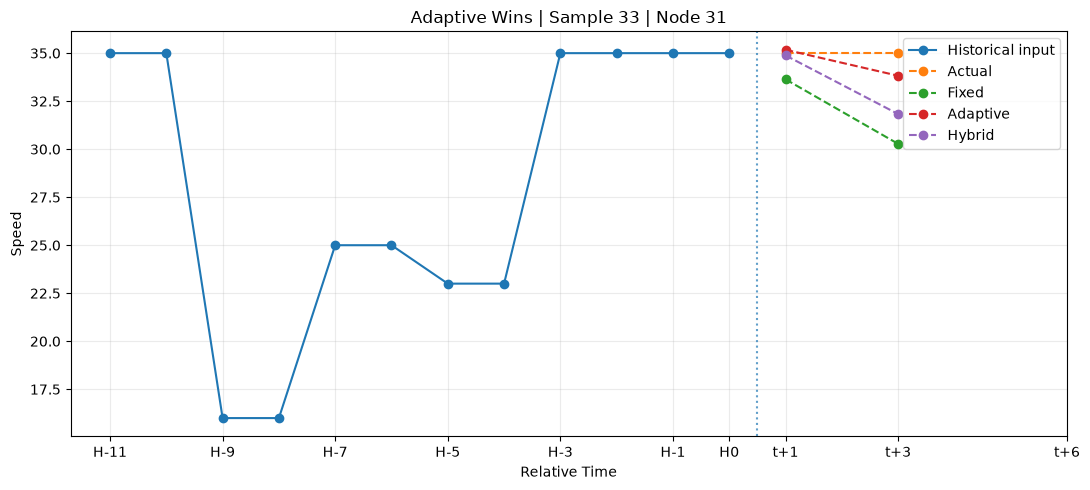

In [51]:
# ============================================================
# INVERSE SCALE HISTORICAL INPUT
# ============================================================

X_test_real = inverse_scale(X_test[..., 0])


# posisi relatif waktu
history_x = np.arange(-11, 1)

future_position = {"t+1": 1, "t+3": 3, "t+6": 6}


# ============================================================
# PLOT EACH REPRESENTATIVE CASE
# ============================================================

for _, case in refined_cases_df.iterrows():
    sample_idx = int(case["sample_idx"])

    node_idx = int(case["node_idx"])

    case_type = case_label_map.get(case["case_type"], case["case_type"])

    # ========================================================
    # HISTORICAL INPUT
    # ========================================================

    history_speed = X_test_real[sample_idx, :, node_idx]

    temp = demo_detail_df[demo_detail_df["case_type"] == case["case_type"]].copy()

    future_x = np.array([future_position[h] for h in temp["horizon"]])

    # ========================================================
    # FIGURE
    # ========================================================

    plt.figure(figsize=(11, 5))

    # historical input
    plt.plot(history_x, history_speed, marker="o", label="Historical input")

    # actual future
    plt.plot(future_x, temp["actual"], marker="o", linestyle="--", label="Actual")

    # fixed
    plt.plot(future_x, temp["fixed_pred"], marker="o", linestyle="--", label="Fixed")

    # adaptive
    plt.plot(future_x, temp["adaptive_pred"], marker="o", linestyle="--", label="Adaptive")

    # hybrid
    plt.plot(future_x, temp["hybrid_pred"], marker="o", linestyle="--", label="Hybrid")

    # batas historical dan forecast
    plt.axvline(x=0.5, linestyle=":", alpha=0.7)

    # ========================================================
    # LABELS
    # ========================================================

    plt.xticks(
        [-11, -9, -7, -5, -3, -1, 0, 1, 3, 6],
        ["H-11", "H-9", "H-7", "H-5", "H-3", "H-1", "H0", "t+1", "t+3", "t+6"],
    )

    plt.xlabel("Relative Time")

    plt.ylabel("Speed")

    plt.title(f"{case_type} | Sample {sample_idx} | Node {node_idx}")

    plt.legend()

    plt.grid(alpha=0.25)

    plt.tight_layout()

    plt.show()

### Ringkasan Hasil Demo Forecast

Grafik di atas menunjukkan bahwa performa setiap strategi graph dapat berbeda pada kondisi lalu lintas yang berbeda.

- **Low-error cases** menunjukkan kondisi ketika pola historis relatif mudah diprediksi. Pada kondisi ini, Fixed, Adaptive, dan Hybrid umumnya menghasilkan prediksi yang dekat dengan nilai aktual.

- **Typical cases** menunjukkan kondisi yang lebih umum, yaitu ketika terdapat perubahan pola pada data historis maupun pada target prediksi. Pada kondisi ini, tidak selalu ada satu model yang unggul pada setiap horizon. Sebagai contoh, Hybrid dapat lebih baik pada t+1, sedangkan Fixed atau Adaptive dapat lebih baik pada t+3.

- **High-error cases** menunjukkan kondisi yang lebih sulit, terutama ketika terjadi perubahan atau lonjakan kecepatan yang tidak dapat diperkirakan dengan jelas dari 12 timestep historis. Pada kondisi tersebut, ketiga model dapat menghasilkan error yang lebih besar.

- **Fixed Wins** menunjukkan bahwa Fixed Graph masih dapat memberikan prediksi terbaik pada kasus tertentu. Hal ini menunjukkan bahwa hubungan geografis yang telah ditentukan tetap memiliki informasi yang berguna untuk forecasting.

- **Adaptive Wins** menunjukkan bahwa learned graph dapat memberikan keuntungan pada kondisi tertentu karena model dapat mempelajari dependency antarkoridor yang tidak hanya bergantung pada kedekatan geografis.

Secara keseluruhan, **Hybrid tidak selalu menjadi model terbaik pada setiap sample individual**. Namun, hasil evaluasi multi-seed menunjukkan bahwa Hybrid menghasilkan rata-rata **MAE dan RMSE terendah pada t+1, t+3, dan t+6**. Hal ini menunjukkan bahwa kombinasi fixed geographic graph dan adaptive learned graph memberikan performa yang lebih konsisten secara keseluruhan.

Demo juga menunjukkan salah satu keterbatasan model, yaitu kesulitan dalam memprediksi **perubahan kecepatan yang sangat mendadak** apabila pola tersebut tidak terlihat dengan jelas pada historical input.

## 17. Time-Based Forecast Demo

Bagian ini menampilkan demo prediksi menggunakan waktu aktual.

Untuk setiap representative case ditampilkan:

- 12 jam historical input
- waktu mulai forecast
- nilai aktual pada horizon prediksi
- prediksi Fixed
- prediksi Adaptive
- prediksi Hybrid

Visualisasi ini dibuat agar alur prediksi lebih mudah dipahami dalam konteks waktu nyata.

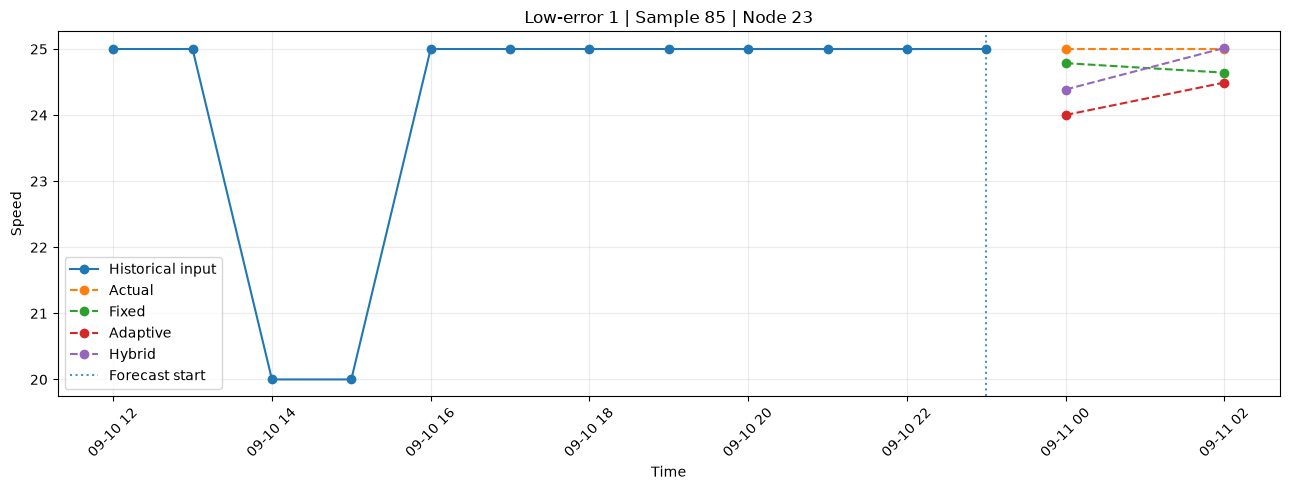

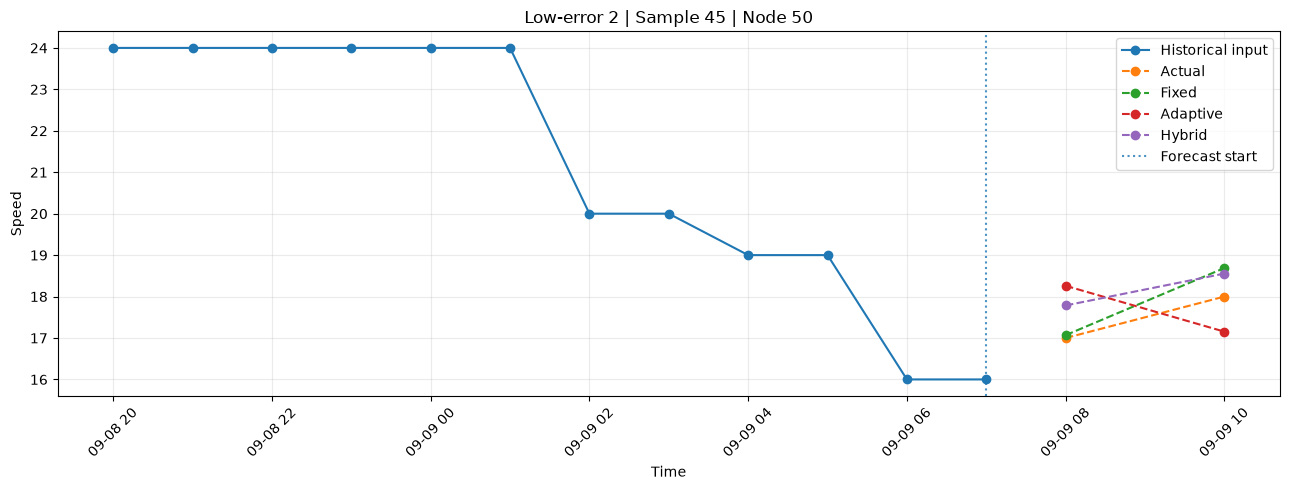

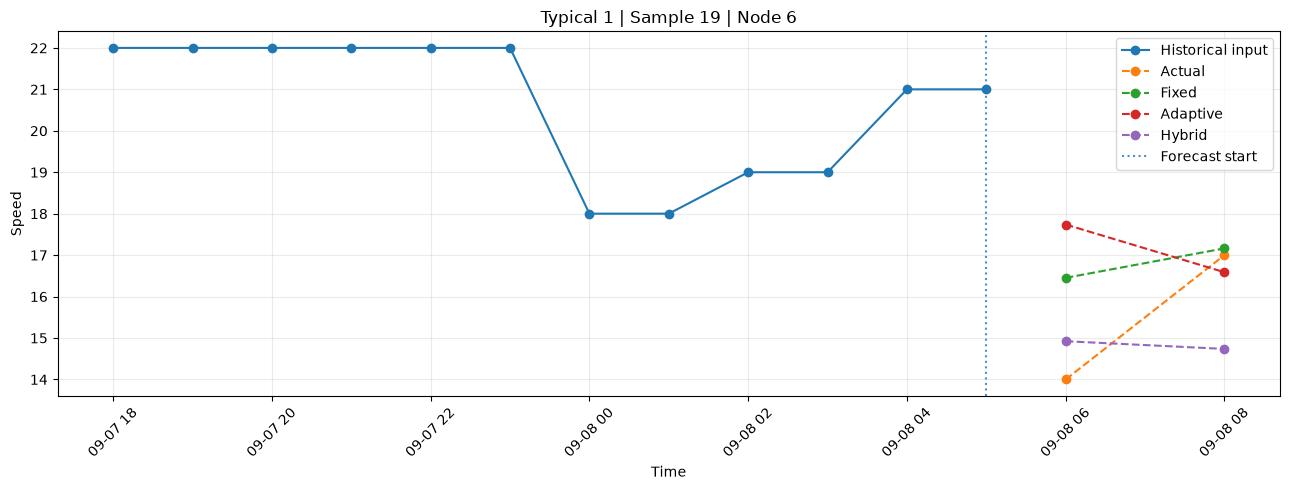

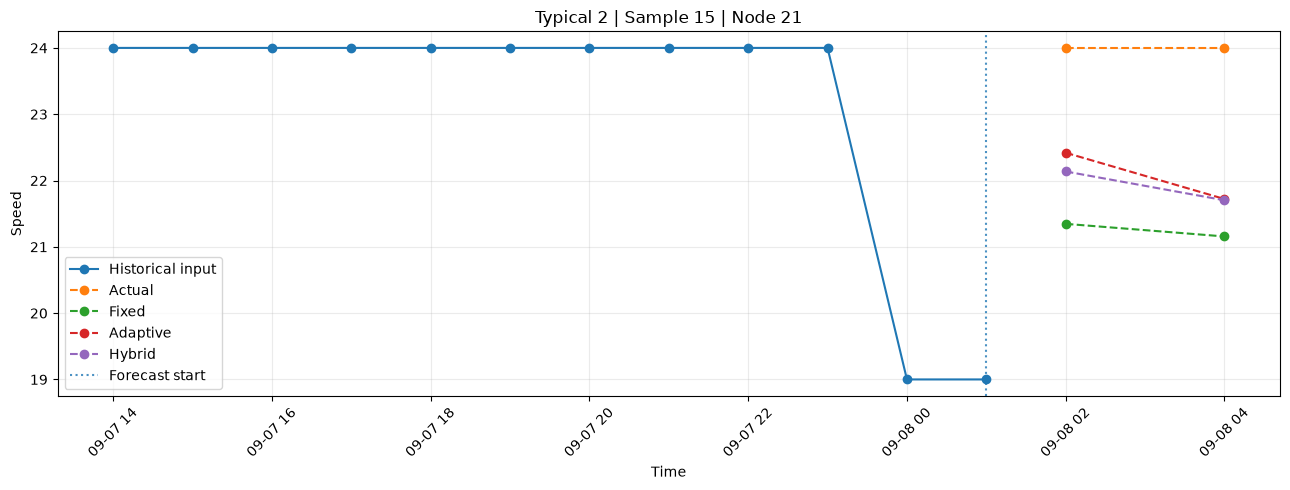

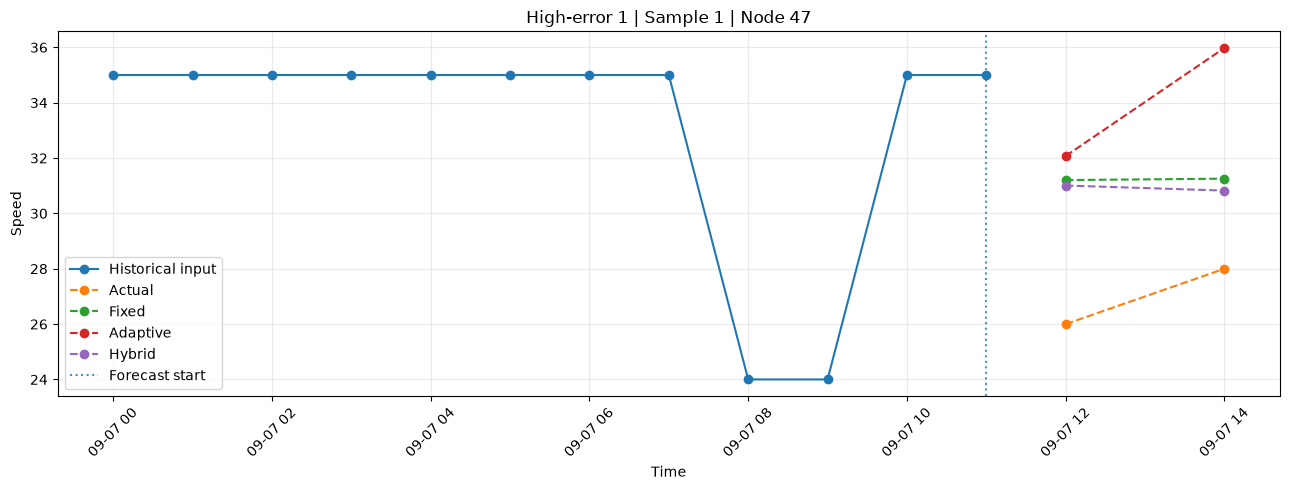

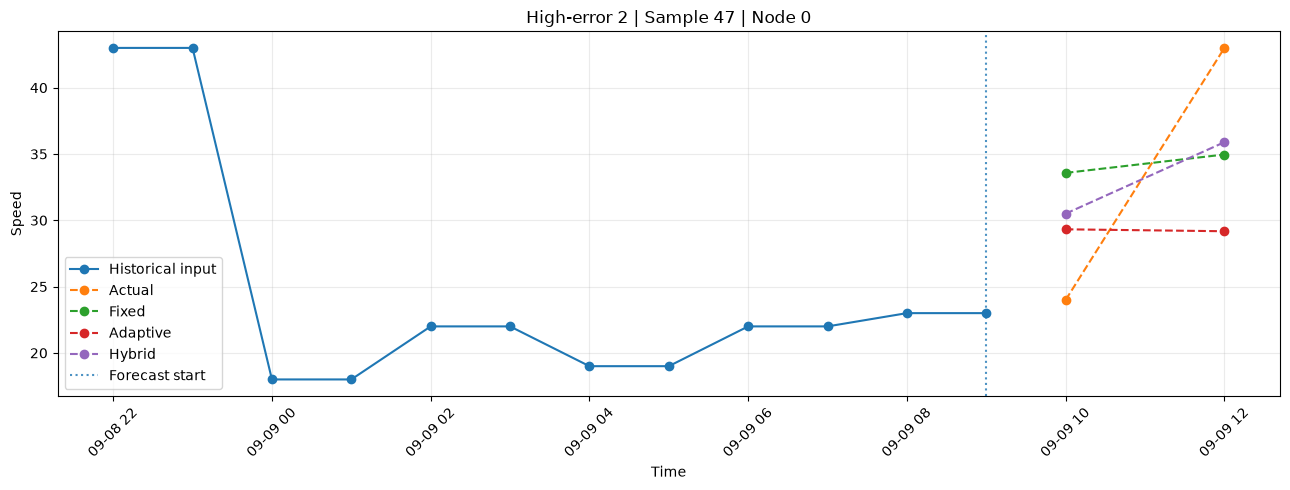

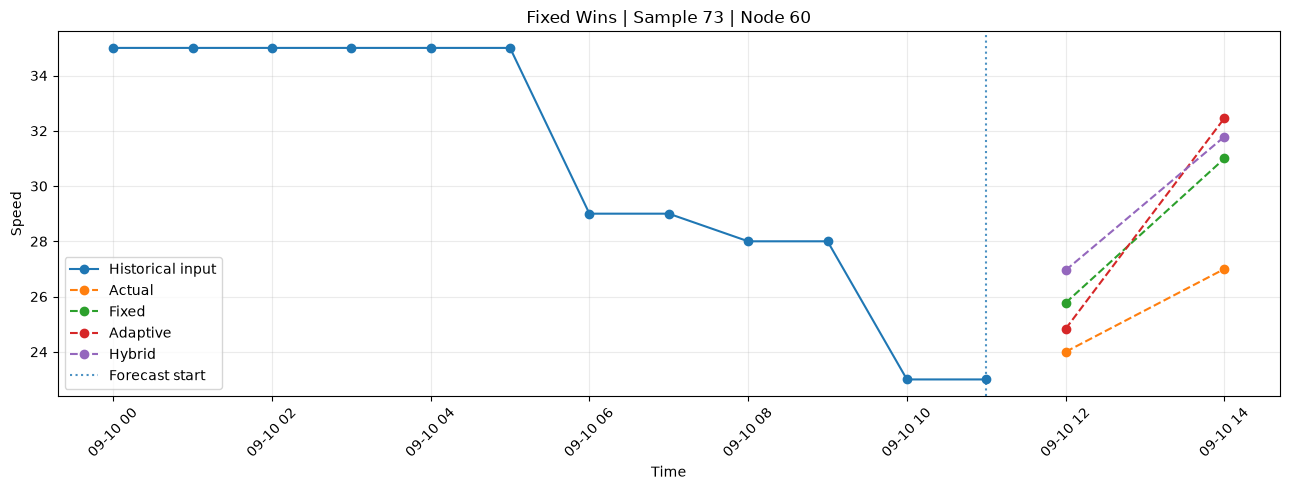

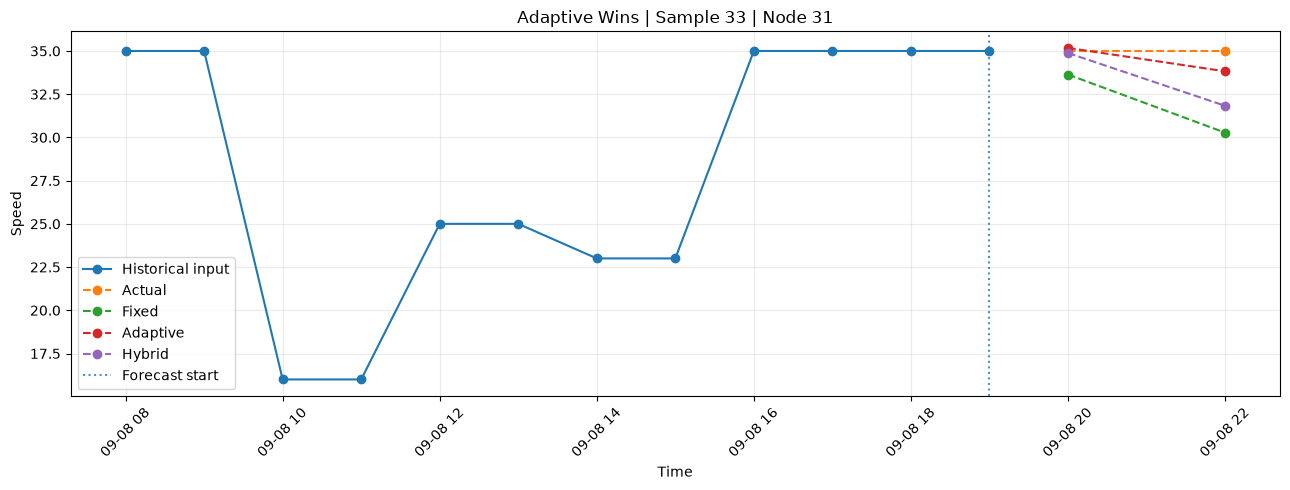

In [52]:
# ============================================================
# TIME-BASED FORECAST DEMO
# ============================================================

import pandas as pd


def to_timestamp(value):

    return pd.Timestamp(value)


for _, case in refined_cases_df.iterrows():
    sample_idx = int(case["sample_idx"])

    node_idx = int(case["node_idx"])

    case_type = case_label_map.get(case["case_type"], case["case_type"])

    # ========================================================
    # TARGET TIMES
    # ========================================================

    temp = demo_detail_df[demo_detail_df["case_type"] == case["case_type"]].copy()

    temp["target_time"] = pd.to_datetime(temp["target_time"])

    # ========================================================
    # REFERENCE TIME
    # ========================================================

    # t+1 = 1 hour after H0
    first_target_time = temp[temp["horizon"] == "t+1"]["target_time"]

    if len(first_target_time) > 0:
        h0_time = first_target_time.iloc[0] - pd.Timedelta(hours=1)

    else:
        # fallback using earliest target
        earliest = temp["target_time"].min()

        horizon_value = int(temp.loc[temp["target_time"].idxmin(), "horizon"].replace("t+", ""))

        h0_time = earliest - pd.Timedelta(hours=horizon_value)

    # ========================================================
    # HISTORICAL TIME AXIS
    # ========================================================

    historical_times = pd.date_range(end=h0_time, periods=12, freq="h")

    history_speed = X_test_real[sample_idx, :, node_idx]

    # ========================================================
    # PLOT
    # ========================================================

    plt.figure(figsize=(13, 5))

    plt.plot(historical_times, history_speed, marker="o", label="Historical input")

    plt.plot(temp["target_time"], temp["actual"], marker="o", linestyle="--", label="Actual")

    plt.plot(temp["target_time"], temp["fixed_pred"], marker="o", linestyle="--", label="Fixed")

    plt.plot(
        temp["target_time"], temp["adaptive_pred"], marker="o", linestyle="--", label="Adaptive"
    )

    plt.plot(temp["target_time"], temp["hybrid_pred"], marker="o", linestyle="--", label="Hybrid")

    # forecast boundary
    plt.axvline(h0_time, linestyle=":", alpha=0.8, label="Forecast start")

    plt.xlabel("Time")

    plt.ylabel("Speed")

    plt.title(f"{case_type} | Sample {sample_idx} | Node {node_idx}")

    plt.xticks(rotation=45)

    plt.legend()

    plt.grid(alpha=0.25)

    plt.tight_layout()

    plt.show()

## 18. Time-Based Forecast Explanation

Bagian ini memberikan penjelasan teks untuk setiap representative case.

Penjelasan mencakup:

- rentang waktu historical input
- waktu terakhir historical input
- waktu target prediksi
- nilai aktual
- prediksi Fixed
- prediksi Adaptive
- prediksi Hybrid
- model dengan absolute error terkecil pada setiap horizon

In [53]:
# ============================================================
# TEXT-BASED FORECAST EXPLANATION
# ============================================================

for _, case in refined_cases_df.iterrows():
    sample_idx = int(case["sample_idx"])

    node_idx = int(case["node_idx"])

    case_type = case_label_map.get(case["case_type"], case["case_type"])

    temp = demo_detail_df[demo_detail_df["case_type"] == case["case_type"]].copy()

    temp["target_time"] = pd.to_datetime(temp["target_time"])

    # ========================================================
    # FIND H0
    # ========================================================

    first_target_time = temp[temp["horizon"] == "t+1"]["target_time"]

    if len(first_target_time) > 0:
        h0_time = first_target_time.iloc[0] - pd.Timedelta(hours=1)

    else:
        earliest_idx = temp["target_time"].idxmin()

        earliest_time = temp.loc[earliest_idx, "target_time"]

        earliest_horizon = int(temp.loc[earliest_idx, "horizon"].replace("t+", ""))

        h0_time = earliest_time - pd.Timedelta(hours=earliest_horizon)

    history_start = h0_time - pd.Timedelta(hours=11)

    # ========================================================
    # HEADER
    # ========================================================

    print("\n" + "=" * 70)

    print(f"{case_type} | Sample {sample_idx} | Node {node_idx}")

    print("=" * 70)

    print(
        "Historical input :",
        history_start.strftime("%Y-%m-%d %H:%M"),
        "s.d.",
        h0_time.strftime("%Y-%m-%d %H:%M"),
    )

    print("Forecast mulai  :", h0_time.strftime("%Y-%m-%d %H:%M"))

    # ========================================================
    # EACH HORIZON
    # ========================================================

    for _, row in temp.iterrows():
        model_errors = {
            "Fixed": row["fixed_abs_error"],
            "Adaptive": row["adaptive_abs_error"],
            "Hybrid": row["hybrid_abs_error"],
        }

        best_model = min(model_errors, key=model_errors.get)

        print("\n", row["horizon"], "| Target time:", row["target_time"].strftime("%Y-%m-%d %H:%M"))

        print(f"  Actual   : {row['actual']:.2f}")

        print(f"  Fixed    : {row['fixed_pred']:.2f} (error {row['fixed_abs_error']:.2f})")

        print(f"  Adaptive : {row['adaptive_pred']:.2f} (error {row['adaptive_abs_error']:.2f})")

        print(f"  Hybrid   : {row['hybrid_pred']:.2f} (error {row['hybrid_abs_error']:.2f})")

        print("  Terbaik  :", best_model)


Low-error 1 | Sample 85 | Node 23
Historical input : 2026-09-10 12:00 s.d. 2026-09-10 23:00
Forecast mulai  : 2026-09-10 23:00

 t+1 | Target time: 2026-09-11 00:00
  Actual   : 25.00
  Fixed    : 24.79 (error 0.21)
  Adaptive : 24.00 (error 1.00)
  Hybrid   : 24.39 (error 0.61)
  Terbaik  : Fixed

 t+3 | Target time: 2026-09-11 02:00
  Actual   : 25.00
  Fixed    : 24.64 (error 0.36)
  Adaptive : 24.49 (error 0.51)
  Hybrid   : 25.02 (error 0.02)
  Terbaik  : Hybrid

Low-error 2 | Sample 45 | Node 50
Historical input : 2026-09-08 20:00 s.d. 2026-09-09 07:00
Forecast mulai  : 2026-09-09 07:00

 t+1 | Target time: 2026-09-09 08:00
  Actual   : 17.00
  Fixed    : 17.07 (error 0.07)
  Adaptive : 18.26 (error 1.26)
  Hybrid   : 17.79 (error 0.79)
  Terbaik  : Fixed

 t+3 | Target time: 2026-09-09 10:00
  Actual   : 18.00
  Fixed    : 18.69 (error 0.69)
  Adaptive : 17.15 (error 0.85)
  Hybrid   : 18.56 (error 0.56)
  Terbaik  : Hybrid

Typical 1 | Sample 19 | Node 6
Historical input : 202

## 19. Representative t+6 Forecast Cases

Pada test set, target t+6 berada pada subset sample yang berbeda dari t+1 dan t+3.

Oleh karena itu, contoh prediksi t+6 ditampilkan secara terpisah.

Case yang dipilih mencakup:

- low-error t+6
- typical t+6
- high-error t+6
- Fixed wins
- Adaptive wins

In [54]:
# ============================================================
# BUILD t+6 CASE TABLE
# ============================================================

t6_rows = []

h_idx = 2  # t+6


for sample_idx in range(y_test_real.shape[0]):
    for node_idx in range(y_test_real.shape[2]):
        if not mask_test[sample_idx, h_idx, node_idx]:
            continue

        actual = float(y_test_real[sample_idx, h_idx, node_idx])

        fixed_pred = float(fixed_pred_real[sample_idx, h_idx, node_idx])

        adaptive_pred = float(adaptive_pred_real[sample_idx, h_idx, node_idx])

        hybrid_pred = float(hybrid_pred_real[sample_idx, h_idx, node_idx])

        fixed_error = abs(fixed_pred - actual)

        adaptive_error = abs(adaptive_pred - actual)

        hybrid_error = abs(hybrid_pred - actual)

        errors = {"fixed": fixed_error, "adaptive": adaptive_error, "hybrid": hybrid_error}

        t6_rows.append(
            {
                "sample_idx": sample_idx,
                "node_idx": node_idx,
                "target_time": target_times_test[sample_idx, h_idx],
                "actual": actual,
                "fixed_pred": fixed_pred,
                "adaptive_pred": adaptive_pred,
                "hybrid_pred": hybrid_pred,
                "fixed_error": fixed_error,
                "adaptive_error": adaptive_error,
                "hybrid_error": hybrid_error,
                "best_model": min(errors, key=errors.get),
            }
        )


t6_df = pd.DataFrame(t6_rows)


print("Total valid t+6 cases:", len(t6_df))

display(t6_df["hybrid_error"].describe())

print("\nBest model counts:")

display(t6_df["best_model"].value_counts().rename_axis("best_model").reset_index(name="count"))

Total valid t+6 cases: 3008


count    3008.000000
mean        2.357840
std         2.962254
min         0.001629
25%         0.625006
50%         1.491302
75%         3.037824
max        37.750835
Name: hybrid_error, dtype: float64


Best model counts:


,best_model,count
0,hybrid,1060
1,adaptive,985
2,fixed,963


## 20. Representative t+6 Cases

Karena target t+6 berada pada subset test yang berbeda dari t+1 dan t+3, contoh t+6 ditampilkan secara terpisah.

Case dipilih untuk menunjukkan:

- low-error case
- typical case
- high-error case
- Fixed outperforming Hybrid
- Adaptive outperforming Hybrid

In [55]:
# ============================================================
# SELECT REPRESENTATIVE t+6 CASES
# ============================================================


def closest_quantile_row(df, column, quantile):

    target = df[column].quantile(quantile)

    idx = df[column].sub(target).abs().idxmin()

    return df.loc[idx].copy()


selected_t6 = []


# ============================================================
# LOW ERROR
# ============================================================

low_case = closest_quantile_row(t6_df, "hybrid_error", 0.10)

low_case["case_type"] = "Low-error t+6"

selected_t6.append(low_case)


# ============================================================
# TYPICAL
# ============================================================

typical_case = closest_quantile_row(t6_df, "hybrid_error", 0.50)

typical_case["case_type"] = "Typical t+6"

selected_t6.append(typical_case)


# ============================================================
# HIGH ERROR
# ============================================================

high_case = closest_quantile_row(t6_df, "hybrid_error", 0.90)

high_case["case_type"] = "High-error t+6"

selected_t6.append(high_case)


# ============================================================
# FIXED WINS
# ============================================================

fixed_t6 = t6_df[t6_df["best_model"] == "fixed"].copy()

fixed_t6["gap"] = fixed_t6["hybrid_error"] - fixed_t6["fixed_error"]

fixed_t6 = fixed_t6[fixed_t6["gap"] > 0]

fixed_win_case = closest_quantile_row(fixed_t6, "gap", 0.75)

fixed_win_case["case_type"] = "Fixed Wins t+6"

selected_t6.append(fixed_win_case)


# ============================================================
# ADAPTIVE WINS
# ============================================================

adaptive_t6 = t6_df[t6_df["best_model"] == "adaptive"].copy()

adaptive_t6["gap"] = adaptive_t6["hybrid_error"] - adaptive_t6["adaptive_error"]

adaptive_t6 = adaptive_t6[adaptive_t6["gap"] > 0]

adaptive_win_case = closest_quantile_row(adaptive_t6, "gap", 0.75)

adaptive_win_case["case_type"] = "Adaptive Wins t+6"

selected_t6.append(adaptive_win_case)


# ============================================================
# FINAL TABLE
# ============================================================

selected_t6_df = pd.DataFrame(selected_t6)


selected_t6_df = selected_t6_df[
    [
        "case_type",
        "sample_idx",
        "node_idx",
        "target_time",
        "actual",
        "fixed_pred",
        "adaptive_pred",
        "hybrid_pred",
        "fixed_error",
        "adaptive_error",
        "hybrid_error",
        "best_model",
    ]
].reset_index(drop=True)


display(selected_t6_df.round(3))

/var/folders/2x/yznypdvj28bc1rg2rmbjkpmc0000gn/T/ipykernel_75550/1302058571.py:188: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  selected_t6_df.round(3)


,case_type,sample_idx,node_idx,target_time,actual,fixed_pred,adaptive_pred,hybrid_pred,fixed_error,adaptive_error,hybrid_error,best_model
0,Low-error t+6,40,8,2026-09-09 08:00:00+00:00,34.0,37.183,33.300,33.783,3.183,0.700,0.217,hybrid
1,Typical t+6,36,5,2026-09-09 04:00:00+00:00,29.0,31.595,27.538,30.488,2.595,1.462,1.488,adaptive
2,High-error t+6,38,23,2026-09-09 06:00:00+00:00,18.0,23.598,23.000,23.229,5.598,5.000,5.229,adaptive
3,Fixed Wins t+6,8,47,2026-09-08 00:00:00+00:00,35.0,33.584,32.352,32.094,1.416,2.648,2.906,fixed
4,Adaptive Wins t+6,66,30,2026-09-10 10:00:00+00:00,22.0,23.438,22.051,20.385,1.438,0.051,1.615,adaptive


## 21. Time-Based Explanation for t+6 Cases

Bagian ini menjelaskan beberapa representative case untuk horizon t+6.

Untuk setiap case ditampilkan:

- rentang historical input
- waktu mulai forecast
- target time t+6
- nilai aktual
- prediksi Fixed
- prediksi Adaptive
- prediksi Hybrid
- absolute error masing-masing model
- model dengan error terkecil

In [56]:
# ============================================================
# TEXT EXPLANATION FOR t+6
# ============================================================

for _, row in selected_t6_df.iterrows():
    sample_idx = int(row["sample_idx"])

    node_idx = int(row["node_idx"])

    target_time = pd.Timestamp(row["target_time"])

    # ========================================================
    # TIME RANGE
    # ========================================================

    h0_time = target_time - pd.Timedelta(hours=6)

    history_start = h0_time - pd.Timedelta(hours=11)

    # ========================================================
    # BEST MODEL
    # ========================================================

    model_errors = {
        "Fixed": row["fixed_error"],
        "Adaptive": row["adaptive_error"],
        "Hybrid": row["hybrid_error"],
    }

    best_model = min(model_errors, key=model_errors.get)

    # ========================================================
    # PRINT
    # ========================================================

    print("\n" + "=" * 70)

    print(f"{row['case_type']} | Sample {sample_idx} | Node {node_idx}")

    print("=" * 70)

    print(
        "Historical input :",
        history_start.strftime("%Y-%m-%d %H:%M"),
        "s.d.",
        h0_time.strftime("%Y-%m-%d %H:%M"),
    )

    print("Forecast mulai  :", h0_time.strftime("%Y-%m-%d %H:%M"))

    print("t+6 target time :", target_time.strftime("%Y-%m-%d %H:%M"))

    print(f"\n  Actual   : {row['actual']:.2f}")

    print(f"  Fixed    : {row['fixed_pred']:.2f} (error {row['fixed_error']:.2f})")

    print(f"  Adaptive : {row['adaptive_pred']:.2f} (error {row['adaptive_error']:.2f})")

    print(f"  Hybrid   : {row['hybrid_pred']:.2f} (error {row['hybrid_error']:.2f})")

    print("  Terbaik  :", best_model)


Low-error t+6 | Sample 40 | Node 8
Historical input : 2026-09-08 15:00 s.d. 2026-09-09 02:00
Forecast mulai  : 2026-09-09 02:00
t+6 target time : 2026-09-09 08:00

  Actual   : 34.00
  Fixed    : 37.18 (error 3.18)
  Adaptive : 33.30 (error 0.70)
  Hybrid   : 33.78 (error 0.22)
  Terbaik  : Hybrid

Typical t+6 | Sample 36 | Node 5
Historical input : 2026-09-08 11:00 s.d. 2026-09-08 22:00
Forecast mulai  : 2026-09-08 22:00
t+6 target time : 2026-09-09 04:00

  Actual   : 29.00
  Fixed    : 31.60 (error 2.60)
  Adaptive : 27.54 (error 1.46)
  Hybrid   : 30.49 (error 1.49)
  Terbaik  : Adaptive

High-error t+6 | Sample 38 | Node 23
Historical input : 2026-09-08 13:00 s.d. 2026-09-09 00:00
Forecast mulai  : 2026-09-09 00:00
t+6 target time : 2026-09-09 06:00

  Actual   : 18.00
  Fixed    : 23.60 (error 5.60)
  Adaptive : 23.00 (error 5.00)
  Hybrid   : 23.23 (error 5.23)
  Terbaik  : Adaptive

Fixed Wins t+6 | Sample 8 | Node 47
Historical input : 2026-09-07 07:00 s.d. 2026-09-07 18:00
F

### Ringkasan Demo t+6

Hasil prediksi t+6 menunjukkan bahwa performa setiap strategi graph dapat berbeda tergantung kondisi data.

- Pada **Low-error t+6**, Hybrid menghasilkan prediksi paling dekat dengan nilai aktual. Hal ini menunjukkan bahwa kombinasi fixed dan adaptive graph dapat memberikan hasil yang sangat baik pada kondisi tertentu.

- Pada **Typical t+6**, Adaptive sedikit lebih baik dibanding Hybrid, meskipun keduanya memiliki error yang hampir sama.

- Pada **High-error t+6**, seluruh model mengalami kesulitan memprediksi nilai aktual. Hal ini menunjukkan bahwa prediksi horizon yang lebih jauh tetap lebih menantang, terutama jika terjadi perubahan pola yang tidak terlihat jelas dari historical input.

- Pada **Fixed Wins t+6**, Fixed Graph menghasilkan error paling kecil. Hal ini menunjukkan bahwa informasi hubungan geografis tetap penting pada beberapa kondisi.

- Pada **Adaptive Wins t+6**, Adaptive Graph menghasilkan prediksi yang sangat dekat dengan nilai aktual. Hal ini menunjukkan bahwa learned graph dapat menangkap dependency tertentu yang tidak selalu diperoleh dari fixed graph.

Secara keseluruhan, Hybrid tidak selalu menjadi model terbaik pada setiap sample t+6. Namun, pada evaluasi keseluruhan test set dan multi-seed, Hybrid tetap memberikan error rata-rata paling rendah. Dengan demikian, Hybrid memberikan performa yang lebih konsisten secara agregat, sedangkan Fixed dan Adaptive dapat unggul pada kondisi tertentu.

## 22. Training and Validation Loss

Bagian ini menampilkan kurva training loss dan validation loss untuk:

- Fixed Graph WaveNet
- Adaptive Graph WaveNet
- Hybrid Graph WaveNet

Kurva ini digunakan untuk melihat:

- apakah proses training berjalan stabil
- kapan validation loss mencapai nilai terbaik
- apakah terjadi tanda overfitting
- perbedaan pola konvergensi antar-model

In [57]:
# ============================================================
# LOAD TRAINING HISTORY
# ============================================================

history_files = {
    "Fixed": (RESULT_DIR / "graphwavenet_fixed_seed42_history.csv"),
    "Adaptive": (RESULT_DIR / "graphwavenet_adaptive_seed42_history.csv"),
    "Hybrid": (RESULT_DIR / "graphwavenet_hybrid_seed42_history.csv"),
}


history_data = {}


for model_name, file_path in history_files.items():
    df = pd.read_csv(file_path)

    history_data[model_name] = df

    print(
        model_name,
        "epochs:",
        len(df),
        "| best epoch:",
        df["val_loss"].idxmin() + 1,
        "| best val_loss:",
        round(df["val_loss"].min(), 6),
    )

Fixed epochs: 83 | best epoch: 58 | best val_loss: 0.139737
Adaptive epochs: 103 | best epoch: 78 | best val_loss: 0.140859
Hybrid epochs: 110 | best epoch: 85 | best val_loss: 0.135763


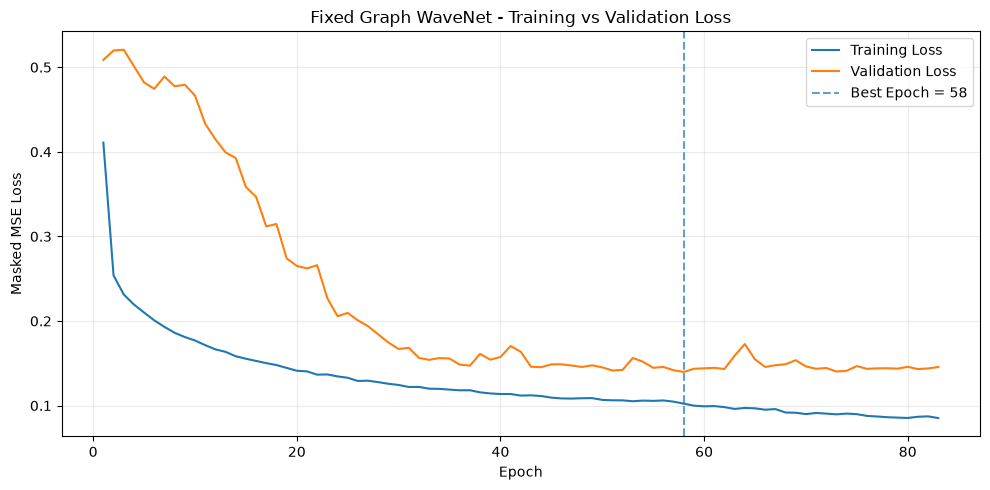

Fixed: best epoch = 58, best val_loss = 0.139737


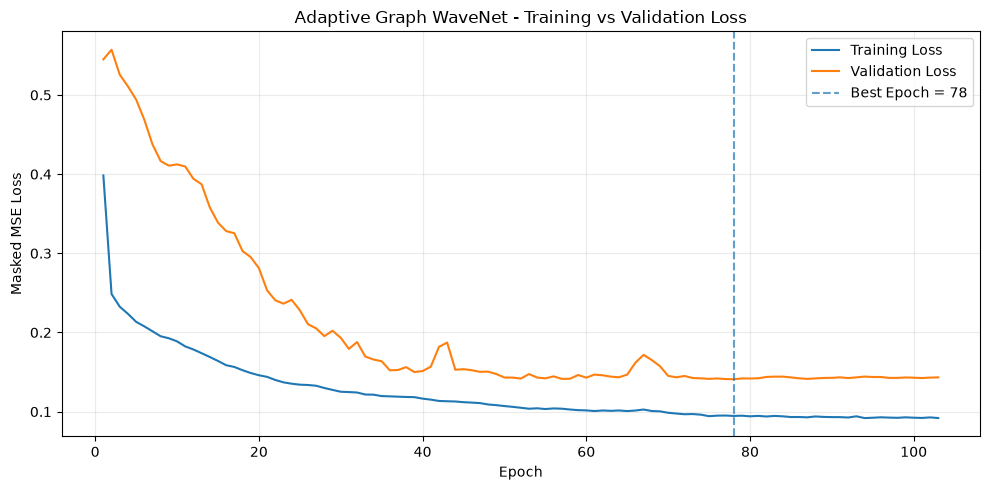

Adaptive: best epoch = 78, best val_loss = 0.140859


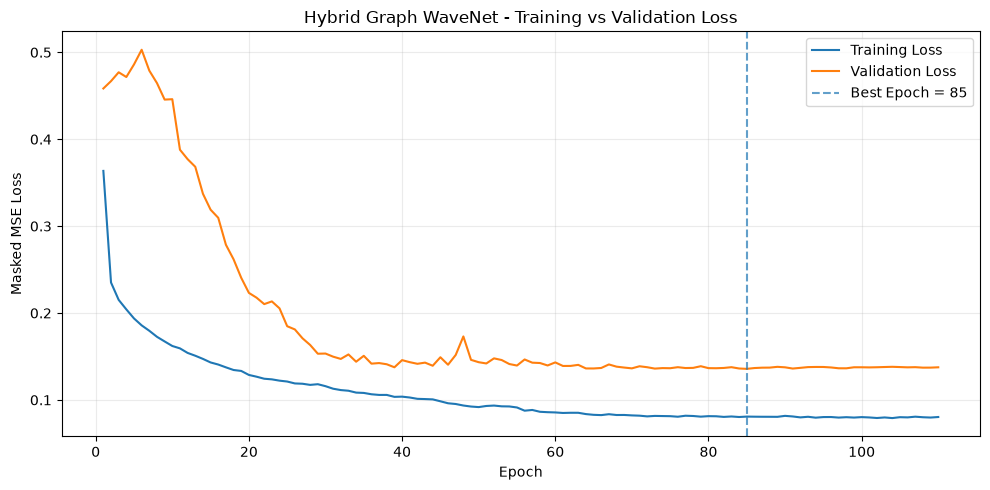

Hybrid: best epoch = 85, best val_loss = 0.135763


In [58]:
# ============================================================
# TRAINING VS VALIDATION LOSS
# ============================================================

for model_name, df in history_data.items():
    best_epoch = df["val_loss"].idxmin() + 1

    best_val = df["val_loss"].min()

    plt.figure(figsize=(10, 5))

    plt.plot(np.arange(1, len(df) + 1), df["loss"], label="Training Loss")

    plt.plot(np.arange(1, len(df) + 1), df["val_loss"], label="Validation Loss")

    plt.axvline(best_epoch, linestyle="--", alpha=0.7, label=(f"Best Epoch = {best_epoch}"))

    plt.xlabel("Epoch")

    plt.ylabel("Masked MSE Loss")

    plt.title(f"{model_name} Graph WaveNet - Training vs Validation Loss")

    plt.legend()

    plt.grid(alpha=0.25)

    plt.tight_layout()

    plt.show()

    print(f"{model_name}: best epoch = {best_epoch}, best val_loss = {best_val:.6f}")

### Ringkasan Training dan Validation

Kurva training dan validation menunjukkan bahwa ketiga model dapat belajar dengan stabil hingga mencapai titik validation loss terbaik.

- **Fixed Graph WaveNet** mencapai validation loss terbaik lebih awal dibanding model lainnya.
- **Adaptive Graph WaveNet** membutuhkan lebih banyak epoch karena model juga mempelajari struktur graph selama proses training.
- **Hybrid Graph WaveNet** membutuhkan proses training yang lebih panjang, tetapi menghasilkan validation loss terbaik yang paling rendah di antara ketiga konfigurasi.

Early stopping digunakan agar training dihentikan ketika validation loss tidak lagi mengalami perbaikan yang berarti.

Secara umum, kurva training dan validation tidak menunjukkan divergence besar yang berkepanjangan. Hal ini menunjukkan bahwa model masih memiliki kemampuan generalisasi yang cukup baik pada validation set.

Perbedaan best epoch antar-model menunjukkan bahwa kompleksitas strategi graph memengaruhi proses konvergensi model.

# 23. Final Conclusion

Penelitian ini membandingkan tiga strategi graph pada Graph WaveNet untuk prediksi kecepatan lalu lintas multi-horizon menggunakan dataset TomTom Final64:

1. **Fixed Graph**
   - menggunakan hubungan geografis antarkoridor
2. **Adaptive Graph**
   - mempelajari dependency antarkoridor langsung dari data
3. **Hybrid Graph**
   - menggabungkan fixed geographic graph dan adaptive learned graph

Dataset menggunakan 12 timestep historical speed sebagai input dan menghasilkan prediksi pada horizon:

- t+1
- t+3
- t+6

Evaluasi dilakukan menggunakan MAE dan RMSE pada lima random seed.

### Hasil utama

Hasil multi-seed menunjukkan bahwa Hybrid Graph WaveNet memperoleh rata-rata error terendah pada seluruh horizon.

| Model | MAE t+1 | MAE t+3 | MAE t+6 |
|---|---:|---:|---:|
| Fixed | 2.4377 | 2.5256 | 2.5482 |
| Adaptive | 2.2814 | 2.4916 | 2.5837 |
| Hybrid | **2.2640** | **2.4047** | **2.4261** |

Hybrid juga memperoleh RMSE rata-rata terendah pada t+1, t+3, dan t+6.

Dibandingkan Fixed Graph, Hybrid menurunkan MAE sebesar:

- 7.13% pada t+1
- 4.79% pada t+3
- 4.79% pada t+6

### Analisis graph

Analisis learned graph menunjukkan bahwa Adaptive dan Hybrid mempelajari hubungan antarkoridor yang sebagian besar berbeda dari fixed geographic graph.

Hal ini menunjukkan bahwa adaptive graph tidak hanya menyalin hubungan geografis, tetapi mempelajari dependency tambahan yang berguna untuk forecasting.

Pada Hybrid, adaptive component cenderung lebih tersebar dibanding Adaptive-only. Hal ini dapat terjadi karena Hybrid juga memperoleh informasi spasial dari fixed geographic graph.

### Analisis demo

Representative cases menunjukkan bahwa Hybrid tidak selalu menjadi model terbaik pada setiap sample individual.

Fixed dan Adaptive masih dapat menghasilkan prediksi yang lebih baik pada kondisi tertentu.

Namun, secara agregat dan multi-seed, Hybrid memberikan performa yang paling konsisten.

Model masih mengalami kesulitan pada kondisi dengan perubahan kecepatan yang sangat mendadak apabila pola tersebut tidak terlihat jelas pada historical input.

### Kesimpulan

Berdasarkan hasil eksperimen, kombinasi fixed geographic graph dan adaptive learned graph pada Hybrid Graph WaveNet memberikan performa terbaik secara keseluruhan untuk prediksi kecepatan lalu lintas multi-horizon pada dataset TomTom Final64.